# Respiratory Infection Diagnosis from Relational Medical Records


**Notebook outline**

1. Setup and data loading
2. EDA, part 1: data quality audit (keys, target, time, missing values, temporal leakage, table-level issues)
3. Data cleaning
4. EDA, part 2: relationships between cleaned variables and the diagnosis
5. Feature engineering
6. Model experiments (feature ablation, algorithm comparison, tuning, ensembling, additional experiments)
7. Final model evaluation and error analysis
8. Model interpretability (feature importance, SHAP, logistic regression coefficients)
9. Final training and submission files

In [2]:
!pip install -q catboost optuna shap

In [3]:
import os
import re
import random
import difflib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import xgboost as xgb
import optuna
import shap
from catboost import CatBoostClassifier

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, log_loss, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

CV_SEEDS = (42, 7, 2024)
FINAL_SEEDS = (42, 7, 2024, 11, 99)
N_FOLDS = 5
RUN_TUNING = False

DATA_DIR = "/content/drive/MyDrive/gdgoc-ugm"

## 1. Data Loading

In [4]:
FILES = {
    "train": "train.csv",
    "test": "test.csv",
    "sample_submission": "sample_submission.csv",
    "index_encounters": "index_encounters.csv",
    "patients": "patients.csv",
    "triage_vitals": "Triase/Triase/triage_vitals.csv",
    "triage_symptoms": "Triase/Triase/triage_symptoms.csv",
    "triage_symptom_severity": "Triase/Triase/triage_symptom_severity.csv",
    "presenting_complaints": "Triase/Triase/presenting_complaints.csv",
    "previous_encounter": "Riwayat Medis/Riwayat Medis/previous_encounter.csv",
    "conditions": "Riwayat Medis/Riwayat Medis/conditions.csv",
    "observations": "Riwayat Medis/Riwayat Medis/observations.csv",
    "medications": "Riwayat Medis/Riwayat Medis/medications.csv",
    "procedures": "Riwayat Medis/Riwayat Medis/procedures.csv",
    "immunizations": "Riwayat Medis/Riwayat Medis/immunizations.csv",
    "allergies": "Riwayat Medis/Riwayat Medis/allergies.csv",
}
data = {name: pd.read_csv(os.path.join(DATA_DIR, path)) for name, path in FILES.items()}

overview = pd.DataFrame({
    "n_rows": {k: d.shape[0] for k, d in data.items()},
    "n_columns": {k: d.shape[1] for k, d in data.items()},
    "missing_cells": {k: int(d.isna().sum().sum()) for k, d in data.items()},
})
overview["missing_pct"] = (100 * overview["missing_cells"] / (overview["n_rows"] * overview["n_columns"])).round(2)
display(overview)

train = data["train"].copy()
test = data["test"].copy()
sample_sub = data["sample_submission"].copy()
idx = data["index_encounters"].copy()
patients = data["patients"].copy()
idx["prediction_time"] = pd.to_datetime(idx["prediction_time"], utc=True, format="mixed")

CLASSES = sorted(train["target_class"].unique())
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
I_STREP = CLASS_TO_ID["strep_pharyngitis"]
I_VIRAL_PHAR = CLASS_TO_ID["viral_pharyngitis"]
print("classes:", CLASSES)

,n_rows,n_columns,missing_cells,missing_pct
train,3600,4,0,0.00
test,1400,3,0,0.00
sample_submission,1400,2,1400,50.00
index_encounters,5000,3,0,0.00
patients,5000,10,5090,10.18
triage_vitals,30000,6,3320,1.84
triage_symptoms,19065,4,0,0.00
triage_symptom_severity,16594,5,765,0.92
presenting_complaints,5000,3,0,0.00
previous_encounter,4471,7,163,0.52


classes: ['acute_bronchitis', 'strep_pharyngitis', 'viral_pharyngitis', 'viral_sinusitis']


## 2. EDA, Part 1: Data Quality Audit

This section inspects the raw tables before any cleaning. Every check prints its result so that each anomaly is visible in the notebook output.

### 2.1 Keys and table relationships

In [5]:
both_splits = pd.concat([train[["patient_id", "encounter_id"]], test[["patient_id", "encounter_id"]]])
pid_check = both_splits.merge(idx[["encounter_id", "patient_id"]], on="encounter_id", how="left",
                              suffixes=("", "_index"))

key_checks = {
    "duplicate sample_id (train)": train["sample_id"].duplicated().sum(),
    "duplicate sample_id (test)": test["sample_id"].duplicated().sum(),
    "duplicate encounter_id (index)": idx["encounter_id"].duplicated().sum(),
    "patients with more than one index encounter": idx["patient_id"].duplicated().sum(),
    "duplicate patient_id (patients.csv)": patients["patient_id"].duplicated().sum(),
    "patients present in both train and test": len(set(train["patient_id"]) & set(test["patient_id"])),
    "train/test encounters missing from index": (~both_splits["encounter_id"].isin(idx["encounter_id"])).sum(),
    "index encounters not in train/test": (~idx["encounter_id"].isin(both_splits["encounter_id"])).sum(),
    "patient_id mismatch between split files and index": (pid_check["patient_id"] != pid_check["patient_id_index"]).sum(),
    "train/test patients missing from patients.csv": (~both_splits["patient_id"].isin(patients["patient_id"])).sum(),
    "sample_submission ids equal test ids (as a set)": set(sample_sub["sample_id"]) == set(test["sample_id"]),
    "sample_submission row order equals test order": bool((sample_sub["sample_id"].values == test["sample_id"].values).all()),
}
display(pd.Series(key_checks, name="value").to_frame())

,value
duplicate sample_id (train),0
duplicate sample_id (test),0
duplicate encounter_id (index),0
patients with more than one index encounter,0
duplicate patient_id (patients.csv),0
patients present in both train and test,0
train/test encounters missing from index,0
index encounters not in train/test,0
patient_id mismatch between split files and index,0
train/test patients missing from patients.csv,0


Each patient has exactly one index encounter and no patient appears in both train and test, so a standard stratified K-fold split is leakage-free at the patient level (no group-based split is needed). The sample submission is ordered differently from `test.csv`, so the submission must be built by merging on `sample_id`.

### 2.2 Target distribution

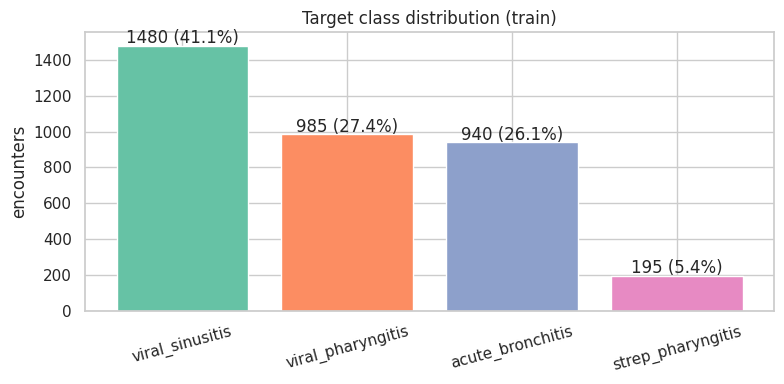

In [6]:
counts = train["target_class"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index, counts.values, color=sns.color_palette("Set2", len(counts)))
for i, v in enumerate(counts.values):
    ax.text(i, v + 15, f"{v} ({v / len(train):.1%})", ha="center")
ax.set_title("Target class distribution (train)")
ax.set_ylabel("encounters")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 2.3 Time coverage of train and test

,min,max,count
split,,,
test,2024-03-27 07:16:35+00:00,2026-10-29 07:40:32+00:00,1400
train,2024-05-22 20:17:27+00:00,2026-10-31 19:05:32+00:00,3600


months with fewer than 20 train encounters (left out of the class-share plot): ['2024-05', '2024-06', '2024-07', '2024-08', '2024-09']


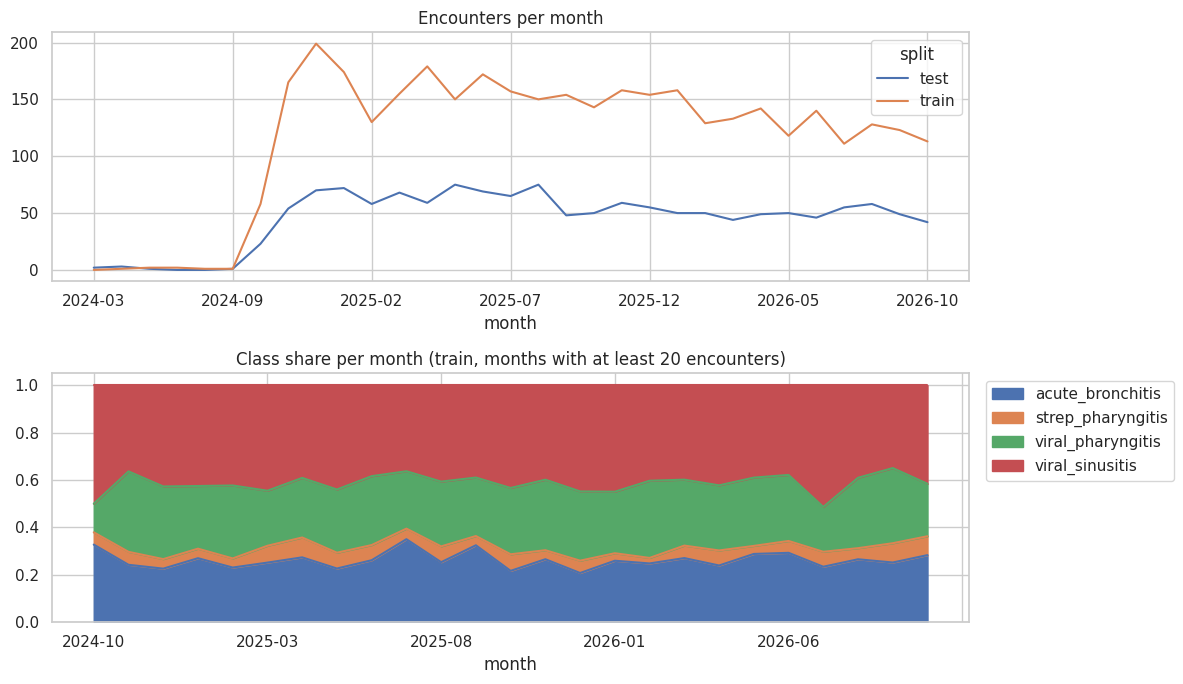

In [7]:
timeline = pd.concat([train.assign(split="train"), test.assign(split="test")]).merge(
    idx[["encounter_id", "prediction_time"]], on="encounter_id", how="left")
timeline["month"] = timeline["prediction_time"].dt.strftime("%Y-%m")
display(timeline.groupby("split")["prediction_time"].agg(["min", "max", "count"]))

monthly = pd.crosstab(timeline["month"], timeline["split"])
train_time = timeline[timeline["split"] == "train"]
month_n = train_time["month"].value_counts()
sparse_months = sorted(month_n[month_n < 20].index)
print("months with fewer than 20 train encounters (left out of the class-share plot):", sparse_months)
class_share = pd.crosstab(train_time["month"], train_time["target_class"], normalize="index")
class_share = class_share.loc[sorted(month_n[month_n >= 20].index)]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
monthly.plot(ax=axes[0])
axes[0].set_title("Encounters per month")
class_share.plot(kind="area", stacked=True, ax=axes[1])
axes[1].set_title("Class share per month (train, months with at least 20 encounters)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Train and test cover the same period, so the split is random rather than temporal. In months with enough encounters the class shares are stable; the apparent spikes in the earliest months come from months containing only a handful of encounters. Calendar time is therefore not treated as a signal.

### 2.4 Missing values

In [8]:
missing_rows = []
for name, d in data.items():
    pct = d.isna().mean() * 100
    for col, p in pct[pct > 0].items():
        missing_rows.append({"table": name, "column": col, "missing_pct": round(p, 2)})
missing_table = pd.DataFrame(missing_rows).sort_values("missing_pct", ascending=False)
display(missing_table)

,table,column,missing_pct
0,sample_submission,target_class,100.00
16,allergies,reaction_code,50.00
18,allergies,reaction_severity,50.00
17,allergies,reaction_name,50.00
3,patients,city,42.32
12,observations,unit,42.11
6,patients,marital_at_visit,36.14
7,triage_vitals,value,11.07
4,patients,county,10.16
13,medications,medication_name,9.26


### 2.5 Temporal leakage audit

Medical history must strictly precede the index encounter's `prediction_time`. Triage records are expected to coincide with it.

In [9]:
HISTORY_TIME = {
    "previous_encounter": "history_start",
    "conditions": "recorded_at",
    "observations": "observed_at",
    "medications": "recorded_at",
    "procedures": "recorded_at",
    "immunizations": "recorded_at",
    "allergies": "recorded_at",
}
TRIAGE_TIME = {"triage_vitals": "measured_at", "triage_symptoms": "observed_at", "triage_symptom_severity": "observed_at"}

audit = []
for name, col in HISTORY_TIME.items():
    d = data[name][["patient_id", col]].copy()
    d["t"] = pd.to_datetime(d[col], utc=True, errors="coerce", format="mixed")
    m = d.merge(idx[["patient_id", "prediction_time"]], on="patient_id", how="left")
    audit.append({"table": name, "rows": len(d), "unparsed_time": int(d["t"].isna().sum()),
                  "key_not_in_index": int(m["prediction_time"].isna().sum()),
                  "before_cutoff": int((m["t"] < m["prediction_time"]).sum()),
                  "after_cutoff": int((m["t"] > m["prediction_time"]).sum()),
                  "same_calendar_day": int((m["t"].dt.date == m["prediction_time"].dt.date).sum())})
for name, col in TRIAGE_TIME.items():
    d = data[name][["encounter_id", col]].copy()
    d["t"] = pd.to_datetime(d[col], utc=True, errors="coerce", format="mixed")
    m = d.merge(idx[["encounter_id", "prediction_time"]], on="encounter_id", how="left")
    gap = (m["t"] - m["prediction_time"]).dt.total_seconds()
    audit.append({"table": name, "rows": len(d), "unparsed_time": int(d["t"].isna().sum()),
                  "key_not_in_index": int(m["prediction_time"].isna().sum()),
                  "before_cutoff": int((gap < 0).sum()),
                  "after_cutoff": int((gap > 1).sum()),
                  "same_calendar_day": int((m["t"].dt.date == m["prediction_time"].dt.date).sum())})
display(pd.DataFrame(audit))

prev_check = data["previous_encounter"][["patient_id", "history_stop"]].copy()
prev_check["stop"] = pd.to_datetime(prev_check["history_stop"], utc=True, errors="coerce", format="mixed")
prev_check = prev_check.merge(idx[["patient_id", "prediction_time"]], on="patient_id", how="left")
print("previous encounters that end after the prediction time:", int((prev_check["stop"] > prev_check["prediction_time"]).sum()))

,table,rows,unparsed_time,key_not_in_index,before_cutoff,after_cutoff,same_calendar_day
0,previous_encounter,4471,0,0,4471,0,37
1,conditions,3583,0,0,3583,0,58
2,observations,55648,0,0,55648,0,805
3,medications,3467,0,0,3467,0,29
4,procedures,17024,0,0,17024,0,141
5,immunizations,1802,0,0,1802,0,23
6,allergies,2,0,0,2,0,0
7,triage_vitals,30000,0,0,0,0,30000
8,triage_symptoms,19065,0,0,0,0,19065
9,triage_symptom_severity,16594,0,0,0,0,16594


previous encounters that end after the prediction time: 0


For triage tables, `after_cutoff` counts records more than one second after `prediction_time` (triage timestamps carry milliseconds while `prediction_time` is truncated to seconds). History tables contain no records after the cutoff. Date-only history records on the same calendar day as the visit are ambiguous, but they are few and are kept. An explicit cutoff filter is still applied during cleaning (Section 3.4) as a safeguard.

### 2.6 Patient table

In [10]:
print("age_at_visit above 110:", int((patients["age_at_visit"] > 110).sum()),
      "| distinct values:", sorted(float(v) for v in patients.loc[patients["age_at_visit"] > 110, "age_at_visit"].unique()))
print("age_at_visit missing:", int(patients["age_at_visit"].isna().sum()))

income_numeric = pd.to_numeric(patients["income_at_visit"], errors="coerce")
non_numeric_income = patients["income_at_visit"][income_numeric.isna() & patients["income_at_visit"].notna()]
print("\nincome values that are not plain numbers:", len(non_numeric_income))
print("examples:", non_numeric_income.sample(min(10, len(non_numeric_income)), random_state=SEED).tolist())

print("\nmarital_at_visit values:", patients["marital_at_visit"].value_counts(dropna=False).to_dict())
print("\ndistinct raw county labels:", patients["county"].nunique())
print("rarest county labels:", patients["county"].value_counts().tail(8).index.tolist())
print("\nstate values:", patients["state"].unique().tolist())

age_at_visit above 110: 19 | distinct values: [999.0]
age_at_visit missing: 60

income values that are not plain numbers: 690
examples: ['112.3k', 'USD 140,815', '87.7k', '$4,102', '$72,593', '112.2k', '$23,285', '343,362', '246,613', '22,678']

marital_at_visit values: {'M': 1852, nan: 1807, 'S': 621, 'D': 455, 'W': 116, 'Married': 80, 'Divorced': 32, 'Single': 27, 'Widowed': 10}

distinct raw county labels: 58
rarest county labels: ['Worcseter County', 'Sfufolk County', 'Hmapden County', 'EssexC ounty', 'Bristol Conuty', 'franklin county', 'Middlseex County', 'Middlese xCounty']

state values: ['Massachusetts']


### 2.7 Triage vitals

In [11]:
vitals = data["triage_vitals"].copy()
display(vitals.groupby(["vital_name", "unit"], dropna=False).size().rename("rows").to_frame())

raw_numeric = pd.to_numeric(vitals["value"], errors="coerce")
comma_decimal = vitals["value"].notna() & raw_numeric.isna()
print("rows per encounter:", vitals.groupby("encounter_id").size().value_counts().to_dict())
print("non-numeric values:", int(comma_decimal.sum()), "| examples:", vitals.loc[comma_decimal, "value"].head(6).tolist())
display((vitals["value"].isna().groupby(vitals["vital_name"]).mean() * 100).round(2).rename("missing_pct").to_frame())
display(raw_numeric.groupby([vitals["vital_name"], vitals["unit"]]).describe().round(2))

rows
vital_name       unit             
BMI              kg/m2        5000
Diastolic BP     kPa           317
                 mmHg         4683
Heart rate       /min         4333
                 beats/min     667
Respiratory rate /min         4338
                 breaths/min   662
SpO2             %            4569
                 fraction      431
Systolic BP      kPa           301
                 mmHg         4699

rows per encounter: {6: 5000}
non-numeric values: 112 | examples: ['18,33', '0,9', '29,85', '9,2', '0,99', '29,54']


,missing_pct
vital_name,
BMI,37.72
Diastolic BP,5.56
Heart rate,6.16
Respiratory rate,5.74
SpO2,5.96
Systolic BP,5.26


count    mean    std    min     25%     50%     75%     max
vital_name       unit                                                                     
BMI              kg/m2        3029.0   27.28  15.73  13.04   23.57   27.79   29.60   304.0
Diastolic BP     kPa           307.0   10.72   5.60   4.00    9.73   10.53   11.20   105.3
                 mmHg         4407.0   83.49  54.92  34.00   73.00   79.00   86.00  1150.0
Heart rate       /min         4031.0   81.38  34.04  39.00   70.00   80.00   90.00   990.0
                 beats/min     661.0   81.26  34.77  42.90   70.00   80.00   89.70   920.0
Respiratory rate /min         4057.0   14.40   7.54   7.15   13.00   14.00   15.00   170.0
                 breaths/min   656.0   14.64   8.67   7.80   13.00   14.00   15.00   150.0
SpO2             %            4275.0   97.58  55.26  58.50   92.00   94.00   96.00   990.0
                 fraction      414.0    0.96   0.43   0.62    0.92    0.94    0.96     9.6
Systolic BP      kPa           292.0   16.23   8.44   9.18   14.37   15.82   17.20   156.0
                 mmHg         4439.0  122.92  76.19  50.70  107.00  118.00  130.00  1390.0

Four problems are visible: values written with a decimal comma, two unit systems for blood pressure (mmHg and kPa) and SpO2 (percent and fraction), implausible maxima (for example heart rates near 1000), and a much higher missing rate for BMI than for the other vitals.

### 2.8 Symptoms, severity and presenting complaints

In [12]:
symptoms = data["triage_symptoms"].copy()
severity = data["triage_symptom_severity"].copy()
complaints = data["presenting_complaints"].copy()

normalized = symptoms["symptom_concept"].str.strip().str.lower()
print("distinct raw symptom labels:", symptoms["symptom_concept"].nunique())
print("distinct labels after lowercasing and stripping whitespace:", normalized.nunique())
print("raw labels with leading or trailing whitespace:",
      int((symptoms["symptom_concept"] != symptoms["symptom_concept"].str.strip()).sum()))
print("symptom rows:", len(symptoms), "| severity rows:", len(severity),
      "| severity rows with a missing score:", int(severity["severity_score"].isna().sum()))
print("encounters with symptoms:", symptoms["encounter_id"].nunique(), "| encounters with severity:", severity["encounter_id"].nunique())
print("severity score range:", severity["severity_score"].min(), "to", severity["severity_score"].max())
print("\nlabels ranked by frequency (top 25):")
display(normalized.value_counts().head(25).rename("rows").to_frame())
print("presenting complaint templates:", complaints["presenting_complaints_text"].nunique())
display(complaints["presenting_complaints_text"].value_counts().rename("encounters").to_frame())

distinct raw symptom labels: 118
distinct labels after lowercasing and stripping whitespace: 70
raw labels with leading or trailing whitespace: 689
symptom rows: 19065 | severity rows: 16594 | severity rows with a missing score: 765
encounters with symptoms: 5000 | encounters with severity: 4961
severity score range: 0.0 to 100.0

labels ranked by frequency (top 25):


,rows
symptom_concept,
throat symptoms,1793
head and facial symptoms,1542
systemic symptoms,1464
cough,1345
nasal symptoms,1250
fever,1203
respiratory secretions,1151
dyspnea/wheeze,615
painful swallowing,437


presenting complaint templates: 8


,encounters
presenting_complaints_text,
"Reports: Cough, Throat symptoms",927
"Reports: Cough, Fever, Throat symptoms",925
Reports: Throat symptoms,861
"Reports: Fever, Throat symptoms",758
Reports: Cough,514
Reports: other respiratory complaints,406
"Reports: Cough, Fever",339
Reports: Fever,270


### 2.9 Medical history coverage and coding consistency

In [13]:
coverage = pd.DataFrame({
    name: {"rows": len(data[name]), "patients": data[name]["patient_id"].nunique(),
           "train_coverage": round(train["patient_id"].isin(data[name]["patient_id"]).mean(), 3),
           "test_coverage": round(test["patient_id"].isin(data[name]["patient_id"]).mean(), 3)}
    for name in HISTORY_TIME}).T
display(coverage)

CODE_LABELS = {
    "previous_encounter": ("history_type_code", "history_description"),
    "conditions": ("condition_code", "condition_name"),
    "observations": ("observation_code", "observation_name"),
    "medications": ("medication_code", "medication_name"),
    "procedures": ("procedure_code", "procedure_name"),
    "immunizations": ("immunization_code", "immunization_name"),
}
for name, (code_col, label_col) in CODE_LABELS.items():
    d = data[name][[code_col, label_col]].dropna()
    labels_per_code = d.assign(label_norm=d[label_col].str.strip().str.lower()).groupby(code_col)["label_norm"].nunique()
    print(f"{name:20s} codes: {data[name][code_col].nunique():4d} | codes with >1 normalized label: "
          f"{(labels_per_code > 1).sum():3d} | missing labels: {data[name][label_col].isna().sum()}")

,rows,patients,train_coverage,test_coverage
previous_encounter,4471.0,4471.0,0.894,0.895
conditions,3583.0,2222.0,0.435,0.469
observations,55648.0,1895.0,0.374,0.393
medications,3467.0,2001.0,0.398,0.406
procedures,17024.0,3111.0,0.621,0.626
immunizations,1802.0,1314.0,0.257,0.278
allergies,2.0,1.0,0.000,0.001


previous_encounter   codes:   38 | codes with >1 normalized label:   8 | missing labels: 163
conditions           codes:  138 | codes with >1 normalized label:  17 | missing labels: 190
observations         codes:  168 | codes with >1 normalized label:  60 | missing labels: 0
medications          codes:  162 | codes with >1 normalized label:  26 | missing labels: 321
procedures           codes:  264 | codes with >1 normalized label:  48 | missing labels: 740
immunizations        codes:   27 | codes with >1 normalized label:   6 | missing labels: 143


### 2.10 Summary of data quality findings

- **Keys** are clean: one index encounter per patient, no train/test patient overlap, and every split row links to the index and patient tables.
- **Class imbalance**: `strep_pharyngitis` is the minority class (about 5%).
- **No temporal leakage** in the provided history tables; triage records coincide with the prediction time.
- **Patients**: an age sentinel value (999), incomes written in several formats (`$`, `USD`, thousands separators, a `k` suffix), marital status mixing codes and words, county names with typos and inconsistent casing, and a constant `state` column.
- **Vitals**: decimal commas, mixed units, and implausible values that are investigated in Section 3.2.
- **Symptoms**: many labels are spelling or whitespace variants and synonyms of the same clinical concept, and some symptoms have no severity row and some severity rows have no score.
- **Presenting complaints** use only a few fixed templates and their redundancy with symptoms is checked in Section 4.4.
- **History** labels are inconsistent (missing names, casing, extra spaces), so codes rather than names are used for features.

## 3. Data Cleaning

### 3.1 Patients

In [14]:
COUNTIES = ["Barnstable", "Berkshire", "Bristol", "Dukes", "Essex", "Franklin", "Hampden",
            "Hampshire", "Middlesex", "Nantucket", "Norfolk", "Plymouth", "Suffolk", "Worcester"]
COUNTY_KEYS = {c.lower() + "county": c + " County" for c in COUNTIES}
MARITAL_MAP = {"Married": "M", "Divorced": "D", "Single": "S", "Widowed": "W"}


def parse_income(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().upper().replace("USD", "").replace("$", "").replace(",", "").strip()
    multiplier = 1
    if s.endswith("K"):
        multiplier = 1000
        s = s[:-1]
    try:
        return float(s) * multiplier
    except ValueError:
        return np.nan


def clean_county(x):
    if pd.isna(x):
        return np.nan
    key = "".join(str(x).lower().split())
    match = difflib.get_close_matches(key, list(COUNTY_KEYS), n=1, cutoff=0.8)
    return COUNTY_KEYS[match[0]] if match else "UNMATCHED"


patients["age"] = patients["age_at_visit"].where(patients["age_at_visit"] <= 110)
patients["income"] = patients["income_at_visit"].apply(parse_income)
patients["marital"] = patients["marital_at_visit"].replace(MARITAL_MAP)
patients["county_clean"] = patients["county"].apply(clean_county)

print("age set to missing (sentinel above 110):", int((patients["age_at_visit"] > 110).sum()),
      "| total missing age after cleaning:", int(patients["age"].isna().sum()))
print("income values that failed to parse:", int((patients["income_at_visit"].notna() & patients["income"].isna()).sum()),
      "| income equal to 0:", int((patients["income"] == 0).sum()))
display(patients["income"].describe().round(0).to_frame())
print("marital categories after mapping:", patients["marital"].value_counts(dropna=False).to_dict())
print("county labels: raw", patients["county"].nunique(), "-> clean", patients["county_clean"].nunique(),
      "| unmatched:", int((patients["county_clean"] == "UNMATCHED").sum()))
print("\ncounty mapping (raw label -> clean label):")
display(patients[["county", "county_clean"]].dropna().drop_duplicates().sort_values(["county_clean", "county"]))

age set to missing (sentinel above 110): 19 | total missing age after cleaning: 79
income values that failed to parse: 0 | income equal to 0: 1


,income
count,4545.0
mean,116146.0
std,168259.0
min,0.0
25%,32829.0
50%,68833.0
75%,124370.0
max,998248.0


marital categories after mapping: {'M': 1932, nan: 1807, 'S': 648, 'D': 487, 'W': 126}
county labels: raw 58 -> clean 14 | unmatched: 0

county mapping (raw label -> clean label):


,county,county_clean
22,Barnstable County,Barnstable County
77,barnstable county,Barnstable County
35,Berkshire County,Berkshire County
79,Berkshire County,Berkshire County
1500,berkshire county,Berkshire County
3891,Bristol Conuty,Bristol County
2,Bristol County,Bristol County
1104,Bristol County,Bristol County
1913,Bristol oCunty,Bristol County
102,bristol county,Bristol County


County typos are resolved by fuzzy matching against the 14 Massachusetts counties after lowercasing and removing whitespaceand the full mapping is printed above for verification. `city` (high missing rate) and `state` (constant) are not used.

### 3.2 Vitals

Cleaning steps, in order:

1. Replace decimal commas with dots.
2. Convert kPa to mmHg (×7.50062) and SpO2 fractions to percent (×100).
3. For values above a plausible physiological range, test two corruption patterns: a tenfold shift (×10) and a ×1.42 multiplier. The ×1.42 pattern was found by inspection: out-of-range SpO2 values such as 132.06, 136.32 and 140.58 are exactly 93, 96 and 99 multiplied by 1.42. A value is restored only if the reversed value falls inside the plausible range; otherwise it is set to missing.
4. For values below the range, restore only those for which multiplying by 1.42 yields a whole number inside the range (the inverse corruption).

In [15]:
PLAUSIBLE = {"BMI": (10, 70), "Diastolic BP": (30, 150), "Systolic BP": (60, 250),
             "Heart rate": (30, 220), "Respiratory rate": (5, 60), "SpO2": (50, 100)}
KPA_TO_MMHG = 7.50062


def is_integer_like(v, tol=0.015):
    return (v - v.round()).abs() < tol


vitals["value_num"] = pd.to_numeric(vitals["value"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("values still unparsed after the decimal-comma fix:", int((vitals["value"].notna() & vitals["value_num"].isna()).sum()))

vitals["value_clean"] = vitals["value_num"]
vitals.loc[vitals["unit"] == "kPa", "value_clean"] *= KPA_TO_MMHG
vitals.loc[vitals["unit"] == "fraction", "value_clean"] *= 100

vital_log = []
for vital, (lo, hi) in PLAUSIBLE.items():
    in_vital = vitals["vital_name"] == vital
    high = in_vital & (vitals["value_clean"] > hi)
    low = in_vital & (vitals["value_clean"] < lo)

    v_high = vitals.loc[high, "value_clean"]
    by_10 = (v_high / 10).between(lo, hi)
    by_142 = ~by_10 & (v_high / 1.42).between(lo, hi)
    unresolved = ~(by_10 | by_142)
    vitals.loc[by_10[by_10].index, "value_clean"] = v_high[by_10] / 10
    vitals.loc[by_142[by_142].index, "value_clean"] = v_high[by_142] / 1.42
    vitals.loc[unresolved[unresolved].index, "value_clean"] = np.nan

    v_low = vitals.loc[low, "value_clean"]
    restore = is_integer_like(v_low * 1.42) & (v_low * 1.42).between(lo, hi)
    vitals.loc[restore[restore].index, "value_clean"] = v_low[restore] * 1.42

    vital_log.append({"vital": vital, "above_range": int(high.sum()), "fixed_div_10": int(by_10.sum()),
                      "fixed_div_1.42": int(by_142.sum()), "set_missing": int(unresolved.sum()),
                      "below_range": int(low.sum()), "restored_mul_1.42": int(restore.sum())})
display(pd.DataFrame(vital_log))
display(vitals.groupby("vital_name")["value_clean"].describe().round(1))

values still unparsed after the decimal-comma fix: 0


,vital,above_range,fixed_div_10,fixed_div_1.42,set_missing,below_range,restored_mul_1.42
0,BMI,13,13,0,0,0,0
1,Diastolic BP,24,23,1,0,0,0
2,Systolic BP,23,23,0,0,6,1
3,Heart rate,9,9,0,0,0,0
4,Respiratory rate,16,16,0,0,0,0
5,SpO2,42,19,23,0,0,0


,count,mean,std,min,25%,50%,75%,max
vital_name,,,,,,,,
BMI,3114.0,26.3,4.9,13.0,23.5,27.8,29.5,48.4
Diastolic BP,4722.0,79.6,11.8,30.0,73.0,79.0,85.1,149.1
Heart rate,4692.0,80.0,11.8,39.0,70.0,80.0,90.0,144.8
Respiratory rate,4713.0,14.0,1.7,7.2,13.0,14.0,15.0,25.6
SpO2,4702.0,93.8,3.4,58.5,92.0,94.0,96.0,99.7
Systolic BP,4737.0,117.7,16.6,54.0,107.0,118.0,129.0,221.5


The check below counts decimal values that become whole numbers after dividing or multiplying by 1.42, and compares the count with two control factors (1.37 and 1.47) that measure how often this happens by chance. Values that are naturally decimal are excluded: BMI (a ratio of weight to squared height) and readings recorded in kPa or as a fraction.

In [16]:
in_range_check = vitals[(vitals["vital_name"] != "BMI") & ~vitals["unit"].isin(["kPa", "fraction"])
                        & vitals["value_clean"].notna()]
v = in_range_check["value_clean"]
has_decimal = (v - v.round()).abs() > 0.001
factor_counts = {}
for f in [1.37, 1.42, 1.47]:
    hit = has_decimal & (is_integer_like(v / f) | is_integer_like(v * f))
    factor_counts[f"factor_{f}"] = hit.groupby(in_range_check["vital_name"]).sum()
display(pd.DataFrame(factor_counts))

,factor_1.37,factor_1.42,factor_1.47
vital_name,,,
Diastolic BP,22,32,16
Heart rate,19,35,22
Respiratory rate,21,40,17
SpO2,17,12,20
Systolic BP,16,28,19


The excess for factor 1.42 over the controls is small (well under 1% of each vital) and cannot be separated reliably from chance, because these vitals are not always recorded as whole numbers. In-range values are therefore left unchanged and this residual corruption is noted as a limitation.

### 3.3 Symptoms: normalization and clinical grouping

Labels are lowercased and stripped, then mapped to clinical groups. The respiratory labels form eight groups of synonyms (for example `sore throat`, `throat pain`, `throat discomfort` and `painful swallowing` all describe the throat). Labels outside these groups are non-respiratory complaints and are grouped as `other`.

In [17]:
GROUP_MAP = {
    "throat symptoms": "throat", "sore throat": "throat", "throat pain": "throat",
    "throat discomfort": "throat", "painful swallowing": "throat",
    "cough": "cough", "persistent cough": "cough", "cough symptom": "cough",
    "coughing": "cough", "cough / productive": "cough",
    "fever": "fever", "raised temperature": "fever", "febrile feeling": "fever",
    "feverish": "fever", "temperature complaint": "fever",
    "nasal symptoms": "nasal", "nasal congestion": "nasal", "nasal complaints": "nasal",
    "blocked nose": "nasal", "stuffy nose": "nasal",
    "systemic symptoms": "systemic", "body malaise": "systemic", "general malaise": "systemic",
    "general fatigue symptoms": "systemic", "feeling unwell": "systemic",
    "respiratory secretions": "secretion", "sputum production": "secretion",
    "mucus complaint": "secretion", "airway secretions": "secretion", "mucus / discharge": "secretion",
    "dyspnea/wheeze": "dyspnea", "difficulty breathing": "dyspnea", "breathing discomfort": "dyspnea",
    "wheezy feeling": "dyspnea", "shortness of breath / wheeze": "dyspnea",
    "head and facial symptoms": "head_face",
    "ear pressure": "ear",
}
MAIN_GROUPS = ["cough", "dyspnea", "fever", "head_face", "nasal", "secretion", "systemic", "throat"]

symptoms["concept"] = symptoms["symptom_concept"].str.strip().str.lower()
symptoms["group"] = symptoms["concept"].map(GROUP_MAP).fillna("other")
severity["concept"] = severity["symptom_concept"].str.strip().str.lower()
severity["group"] = severity["concept"].map(GROUP_MAP).fillna("other")

print("labels mapped to 'other':")
display(symptoms.loc[symptoms["group"] == "other", "concept"].value_counts().rename("rows").to_frame())
print("duplicate (encounter, concept) pairs after normalization:", int(symptoms.duplicated(["encounter_id", "concept"]).sum()))

pairs = symptoms[["encounter_id", "concept", "group"]].drop_duplicates(["encounter_id", "concept"]).merge(
    severity[["encounter_id", "concept", "severity_score"]].drop_duplicates(["encounter_id", "concept"]),
    on=["encounter_id", "concept"], how="left", indicator=True)
pairs["missing_row"] = (pairs["_merge"] == "left_only").astype(int)
pairs["missing_score"] = ((pairs["_merge"] == "both") & pairs["severity_score"].isna()).astype(int)
sev_keys = set(zip(severity["encounter_id"], severity["concept"]))
sym_keys = set(zip(symptoms["encounter_id"], symptoms["concept"]))
print("severity pairs without a matching symptom:", len(sev_keys - sym_keys))
print("\nshare of symptom pairs without severity, by group:")
display(pairs.groupby("group")[["missing_row", "missing_score"]].mean().round(3))

labels mapped to 'other':


,rows
concept,
frequent urination,216
thirst,195
hunger,189
tingling in hands and feet,75
blurred vision,55
decreased visual perception,32
decreased communication,31
decreased in judgement,30
confusion,30


duplicate (encounter, concept) pairs after normalization: 13
severity pairs without a matching symptom: 0

share of symptom pairs without severity, by group:


,missing_row,missing_score
group,,
cough,0.064,0.044
dyspnea,1.000,0.000
ear,0.100,0.067
fever,0.053,0.045
head_face,0.086,0.042
nasal,0.068,0.040
other,0.057,0.037
secretion,0.064,0.039
systemic,0.155,0.040


### 3.4 Medical history: explicit cutoff filter

In [18]:
history = {}
for name, col in HISTORY_TIME.items():
    if name == "allergies":
        continue
    d = data[name].copy()
    d["event_time"] = pd.to_datetime(d[col], utc=True, errors="coerce", format="mixed")
    d = d.merge(idx[["patient_id", "prediction_time"]], on="patient_id", how="inner")
    keep = d["event_time"] < d["prediction_time"]
    print(f"{name:20s} rows: {len(d):6d} | removed (at or after cutoff, or unparsed time): {int((~keep).sum())}")
    history[name] = d[keep].copy()
print("allergies table not used:", data["allergies"]["patient_id"].nunique(), "patient(s) with records")

previous_encounter   rows:   4471 | removed (at or after cutoff, or unparsed time): 0
conditions           rows:   3583 | removed (at or after cutoff, or unparsed time): 0
observations         rows:  55648 | removed (at or after cutoff, or unparsed time): 0
medications          rows:   3467 | removed (at or after cutoff, or unparsed time): 0
procedures           rows:  17024 | removed (at or after cutoff, or unparsed time): 0
immunizations        rows:   1802 | removed (at or after cutoff, or unparsed time): 0
allergies table not used: 1 patient(s) with records


## 4. EDA, Part 2: Relationships with the Diagnosis

### 4.1 Symptom groups by diagnosis

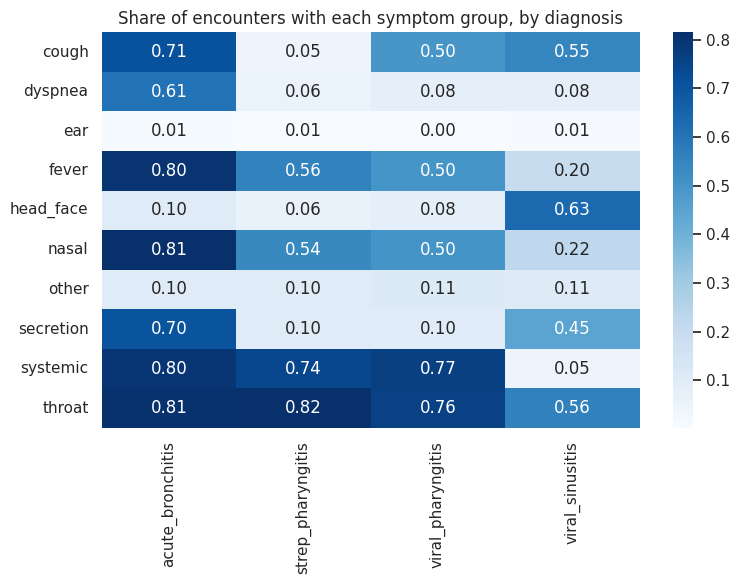

mean number of distinct labels per group (close to the share above means one synonym per group):


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
cough,0.71,0.05,0.50,0.55
dyspnea,0.61,0.06,0.08,0.08
ear,0.01,0.01,0.00,0.01
fever,0.80,0.56,0.50,0.20
head_face,0.10,0.06,0.08,0.63
nasal,0.81,0.54,0.50,0.22
other,0.19,0.19,0.24,0.21
secretion,0.70,0.10,0.10,0.45
systemic,0.91,0.74,0.77,0.05
throat,0.81,0.82,0.76,0.56


In [19]:
labels = train[["encounter_id", "patient_id", "target_class"]]
group_flags = pd.crosstab(symptoms["encounter_id"], symptoms["group"]).clip(upper=1)
by_class = labels.merge(group_flags, left_on="encounter_id", right_index=True, how="left")
prevalence = by_class.groupby("target_class")[list(group_flags.columns)].mean().T

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(prevalence, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Share of encounters with each symptom group, by diagnosis")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

concepts_per_group = labels.merge(pd.crosstab(symptoms["encounter_id"], symptoms["group"]),
                                  left_on="encounter_id", right_index=True, how="left")
print("mean number of distinct labels per group (close to the share above means one synonym per group):")
display(concepts_per_group.groupby("target_class")[list(group_flags.columns)].mean().T.round(2))

### 4.2 Symptom severity by diagnosis

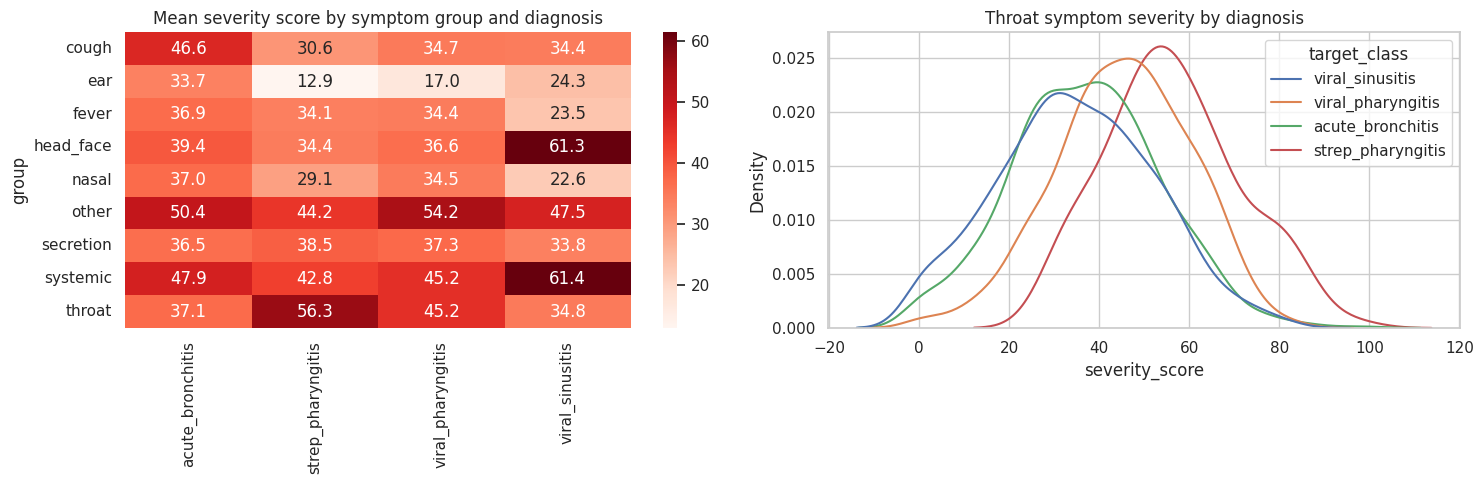

In [20]:
sev_labeled = severity.merge(labels[["encounter_id", "target_class"]], on="encounter_id")
sev_by_class = sev_labeled.pivot_table(index="group", columns="target_class", values="severity_score", aggfunc="mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(sev_by_class, annot=True, fmt=".1f", cmap="Reds", ax=axes[0])
axes[0].set_title("Mean severity score by symptom group and diagnosis")
axes[0].set_xlabel("")
sns.kdeplot(data=sev_labeled[sev_labeled["group"] == "throat"], x="severity_score", hue="target_class",
            common_norm=False, ax=axes[1])
axes[1].set_title("Throat symptom severity by diagnosis")
plt.tight_layout()
plt.show()

### 4.3 Number of symptoms

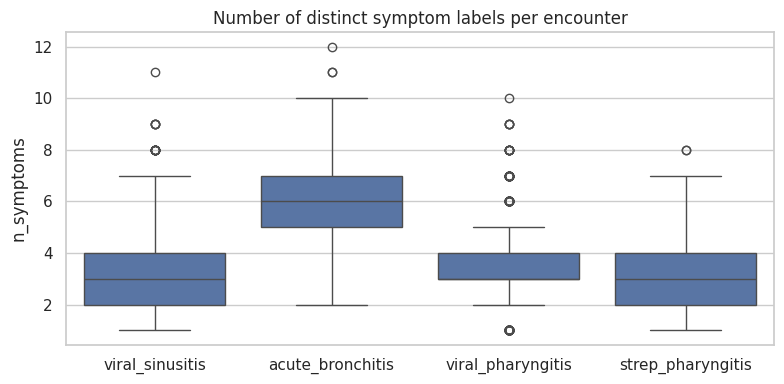

,count,mean,std,min,25%,50%,75%,max
target_class,,,,,,,,
acute_bronchitis,940.0,5.64,1.43,2.0,5.0,6.0,7.0,12.0
strep_pharyngitis,195.0,3.12,1.26,1.0,2.0,3.0,4.0,8.0
viral_pharyngitis,985.0,3.52,1.42,1.0,3.0,3.0,4.0,10.0
viral_sinusitis,1480.0,2.97,1.41,1.0,2.0,3.0,4.0,11.0


In [21]:
n_concepts = symptoms.groupby("encounter_id")["concept"].nunique().rename("n_symptoms")
sym_count = labels.merge(n_concepts, left_on="encounter_id", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sym_count, x="target_class", y="n_symptoms", ax=ax)
ax.set_title("Number of distinct symptom labels per encounter")
ax.set_xlabel("")
plt.tight_layout()
plt.show()
display(sym_count.groupby("target_class")["n_symptoms"].describe().round(2))

### 4.4 Presenting complaints versus symptoms

In [22]:
complaint_text = complaints.set_index("encounter_id")["presenting_complaints_text"].str.lower()
flags_aligned = group_flags.reindex(complaint_text.index).fillna(0)
for g in ["cough", "fever", "throat"]:
    agreement = (complaint_text.str.contains(g).astype(int) == flags_aligned[g].astype(int)).mean()
    print(f"complaint mentions '{g}' == symptom group '{g}' present: {agreement:.4f}")
none_of_three = (flags_aligned[["cough", "fever", "throat"]].sum(axis=1) == 0).astype(int)
print(f"complaint 'other respiratory complaints' == none of cough/fever/throat: "
      f"{(complaint_text.str.contains('other').astype(int) == none_of_three).mean():.4f}")

complaint_by_class = labels.merge(complaints[["encounter_id", "presenting_complaints_text"]], on="encounter_id")
display(pd.crosstab(complaint_by_class["presenting_complaints_text"], complaint_by_class["target_class"]))

complaint mentions 'cough' == symptom group 'cough' present: 1.0000
complaint mentions 'fever' == symptom group 'fever' present: 1.0000
complaint mentions 'throat' == symptom group 'throat' present: 1.0000
complaint 'other respiratory complaints' == none of cough/fever/throat: 1.0000


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
presenting_complaints_text,,,,
Reports: Cough,19,0,57,296
"Reports: Cough, Fever",108,2,61,74
"Reports: Cough, Fever, Throat symptoms",435,3,176,70
"Reports: Cough, Throat symptoms",107,4,194,376
Reports: Fever,40,22,60,70
"Reports: Fever, Throat symptoms",169,82,196,80
Reports: Throat symptoms,47,70,184,306
Reports: other respiratory complaints,15,12,57,208


An agreement of 1.0 means the complaint text is derived entirely from the symptom table, so complaints add no information beyond the symptom groups and are not used as features.

### 4.5 Vitals by diagnosis (after cleaning)

target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
BMI,27.8,26.7,27.8,27.8
Diastolic BP,79.0,78.0,79.0,80.0
Heart rate,79.0,80.0,81.0,80.0
Respiratory rate,14.0,14.0,14.0,14.0
SpO2,94.0,94.0,94.0,94.0
Systolic BP,117.0,118.0,118.0,118.0


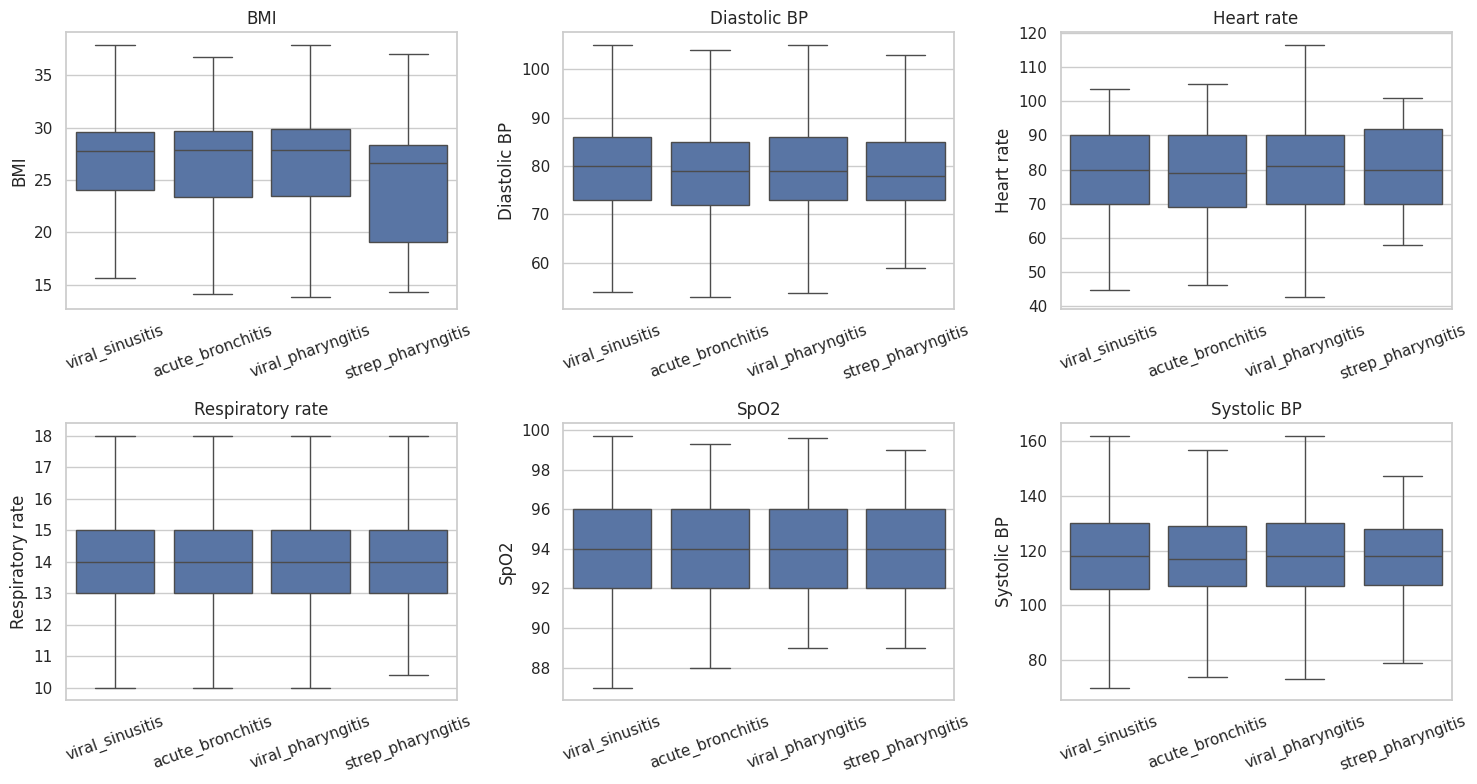

share of encounters recorded with kPa or fraction units, by class (artifact check):


,alt_unit
target_class,
acute_bronchitis,0.194
strep_pharyngitis,0.185
viral_pharyngitis,0.197
viral_sinusitis,0.191


In [23]:
vitals_wide = vitals.pivot_table(index="encounter_id", columns="vital_name", values="value_clean", aggfunc="first")
vit_by_class = labels.merge(vitals_wide, left_on="encounter_id", right_index=True, how="left")
display(vit_by_class.groupby("target_class")[list(vitals_wide.columns)].median().round(1).T)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), vitals_wide.columns):
    sns.boxplot(data=vit_by_class, x="target_class", y=col, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

unit_alt = vitals["unit"].isin(["kPa", "fraction"]).groupby(vitals["encounter_id"]).max().rename("alt_unit")
unit_by_class = labels.merge(unit_alt, left_on="encounter_id", right_index=True, how="left")
print("share of encounters recorded with kPa or fraction units, by class (artifact check):")
display(unit_by_class.groupby("target_class")["alt_unit"].mean().round(3).to_frame())

### 4.6 Age and other demographics

target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis,All
age_group,,,,,
0-2,2,0,2,1,5
3-14,151,74,165,199,589
15-44,399,51,406,659,1515
45-64,249,43,285,395,972
65+,122,24,112,203,461
All,923,192,970,1457,3542


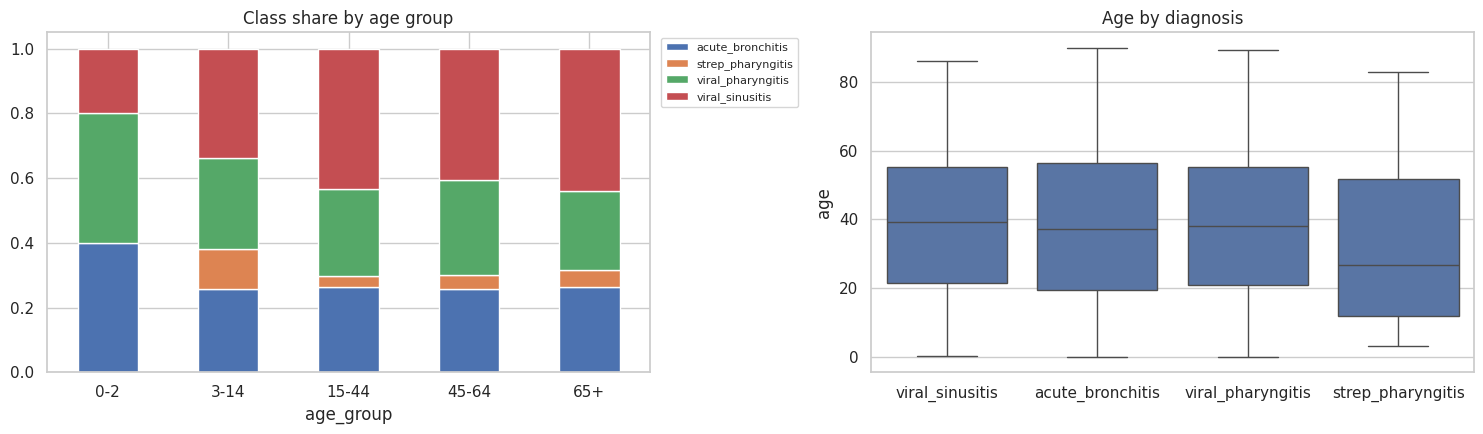

target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
gender,,,,
F,0.268,0.055,0.270,0.406
M,0.253,0.053,0.277,0.417


,median_income
target_class,
acute_bronchitis,66841.0
strep_pharyngitis,70350.0
viral_pharyngitis,66437.5
viral_sinusitis,70822.0


In [24]:
AGE_BINS = [0, 3, 15, 45, 65, 120]
AGE_LABELS = ["0-2", "3-14", "15-44", "45-64", "65+"]
demo = labels.merge(patients[["patient_id", "age", "gender", "income", "race"]], on="patient_id", how="left")
demo["age_group"] = pd.cut(demo["age"], bins=AGE_BINS, right=False, labels=AGE_LABELS)

display(pd.crosstab(demo["age_group"], demo["target_class"], margins=True))
age_share = pd.crosstab(demo["age_group"], demo["target_class"], normalize="index")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
age_share.plot(kind="bar", stacked=True, ax=axes[0], rot=0)
axes[0].set_title("Class share by age group")
axes[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
sns.boxplot(data=demo, x="target_class", y="age", ax=axes[1])
axes[1].set_title("Age by diagnosis")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

display(pd.crosstab(demo["gender"], demo["target_class"], normalize="index").round(3))
display(demo.groupby("target_class")["income"].median().rename("median_income").to_frame())

### 4.7 Medical history by diagnosis

In [25]:
hist_by_class = labels[["patient_id", "target_class"]].copy()
for name, d in history.items():
    hist_by_class[name] = hist_by_class["patient_id"].map(d["patient_id"].value_counts()).fillna(0)
print("share of patients with at least one record:")
display((hist_by_class[list(history)] > 0).groupby(hist_by_class["target_class"]).mean().round(3).T)
print("mean number of records:")
display(hist_by_class.groupby("target_class")[list(history)].mean().round(2).T)

obs_panels = history["observations"].groupby("observation_code")["patient_id"].nunique().sort_values(ascending=False)
print("most frequent observation codes and their patient counts (identical counts indicate fixed panels):")
display(obs_panels.head(20).rename("patients").to_frame())

share of patients with at least one record:


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
previous_encounter,0.911,0.892,0.883,0.891
conditions,0.485,0.379,0.400,0.433
observations,0.466,0.349,0.322,0.353
medications,0.403,0.354,0.398,0.401
procedures,0.637,0.641,0.587,0.630
immunizations,0.297,0.251,0.227,0.252


mean number of records:


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
previous_encounter,0.91,0.89,0.88,0.89
conditions,0.79,0.58,0.64,0.71
observations,13.96,9.24,8.90,10.60
medications,0.75,0.48,0.65,0.68
procedures,3.25,3.67,3.14,3.57
immunizations,0.42,0.34,0.32,0.34


most frequent observation codes and their patient counts (identical counts indicate fixed panels):


,patients
observation_code,
72514-3,1554
8462-4,1520
8480-6,1520
9279-1,1505
8867-4,1505
39156-5,1501
29463-7,1501
72166-2,1501
8302-2,1501


### 4.8 Missing severity by diagnosis

In [26]:
pairs_labeled = pairs.merge(labels[["encounter_id", "target_class"]], on="encounter_id")
display(pairs_labeled.groupby("target_class")[["missing_row", "missing_score"]].mean().round(3))

,missing_row,missing_score
target_class,,
acute_bronchitis,0.199,0.034
strep_pharyngitis,0.113,0.053
viral_pharyngitis,0.083,0.044
viral_sinusitis,0.085,0.042


### 4.9 Key findings

- **Symptom groups are the dominant signal.** Head and facial symptoms characterize viral sinusitis, dyspnea and secretions characterize acute bronchitis, strep pharyngitis is marked by the near absence of cough and secretions.
- **Synonym choice is noise.** The number of distinct labels per group is almost equal to the share of encounters with that group, so an encounter usually carries a single, seemingly random synonym per group. Group-level features are therefore preferred over raw labels (tested in Section 6.2).
- **Strep vs viral pharyngitis is the hardest pair.** Their symptom profiles are nearly identical except for cough. Strep shows higher throat severity and is concentrated in children aged 3 to 14, which matches the Centor criteria used clinically for streptococcal pharyngitis (absence of cough, fever, age).
- **Vitals carry little signal**: medians are almost identical across diagnoses, and the alternative-unit recording rate is the same in every class (no artifact).
- **History carries weak signal**: coverage is identical in train and test, and many codes are recorded as fixed panels or bundles (observation panels, dental procedure bundles, childhood vaccine sets) that reflect visit type more than clinical state.
- **Missing severity differs by class**: being higher for acute bronchitis. It is used as a feature.
- **Presenting complaints are fully redundant** with the symptom groups.

## 5. Feature Engineering

All features are built for the 5,000 index encounters at once (train and test together). No feature uses the target and the selection of history codes is based only on frequency.

### 5.1 Symptom and severity features

In [27]:
feat_sym = idx[["encounter_id"]].copy()
feat_sym = feat_sym.merge(group_flags.add_prefix("sym_"), left_on="encounter_id", right_index=True, how="left")
feat_sym = feat_sym.merge(n_concepts, left_on="encounter_id", right_index=True, how="left")
feat_sym = feat_sym.merge(symptoms[symptoms["group"] != "other"].groupby("encounter_id")["group"].nunique().rename("n_resp_groups"),
                          left_on="encounter_id", right_index=True, how="left")
sev_main = severity[severity["group"].isin(MAIN_GROUPS)]
feat_sym = feat_sym.merge(sev_main.pivot_table(index="encounter_id", columns="group", values="severity_score",
                                               aggfunc="max").add_prefix("sevmax_"),
                          left_on="encounter_id", right_index=True, how="left")
feat_sym = feat_sym.merge(severity.groupby("encounter_id")["severity_score"].agg(["mean", "max"]).add_prefix("sev_"),
                          left_on="encounter_id", right_index=True, how="left")
feat_sym = feat_sym.merge(pairs.groupby("encounter_id")[["missing_row", "missing_score"]].sum().add_prefix("n_sev_"),
                          left_on="encounter_id", right_index=True, how="left")

count_cols = [c for c in feat_sym.columns if c.startswith(("sym_", "n_"))]
feat_sym[count_cols] = feat_sym[count_cols].fillna(0)
print("symptom block:", feat_sym.shape)
print("severity groups available as features:", [c for c in feat_sym.columns if c.startswith("sevmax_")])

symptom block: (5000, 24)
severity groups available as features: ['sevmax_cough', 'sevmax_fever', 'sevmax_head_face', 'sevmax_nasal', 'sevmax_secretion', 'sevmax_systemic', 'sevmax_throat']


- `sym_<group>`: whether the group is present.
- `n_symptoms`, `n_resp_groups`: number of distinct labels and of respiratory groups.
- `sevmax_<group>`: maximum severity in the group (left missing when the group is absent or has no score, which tree models handle natively). Maximum and mean are almost identical because an encounter rarely has more than one label per group, so only the maximum is kept.
- `sev_mean`, `sev_max`: overall severity.
- `n_sev_missing_row`, `n_sev_missing_score`: number of symptoms without a severity row or score.

### 5.2 Vital sign features

In [28]:
feat_vit = vitals_wide.copy()
feat_vit.columns = ["vit_" + c.lower().replace(" ", "_") for c in feat_vit.columns]
feat_vit["vit_n_missing"] = feat_vit.isna().sum(axis=1)
feat_vit = idx[["encounter_id"]].merge(feat_vit, left_on="encounter_id", right_index=True, how="left")
print("vitals block:", feat_vit.shape)

vitals block: (5000, 8)


### 5.3 Demographic features

In [29]:
feat_demo = idx[["encounter_id", "patient_id"]].merge(
    patients[["patient_id", "age", "gender", "income", "race", "ethnicity", "marital", "county_clean"]],
    on="patient_id", how="left").rename(columns={"county_clean": "county"})
feat_demo["child_3_14"] = np.where(feat_demo["age"].isna(), np.nan,
                                   feat_demo["age"].between(3, 15, inclusive="left").astype(float))
feat_demo["gender_male"] = (feat_demo["gender"] == "M").astype(int)
feat_demo = feat_demo.drop(columns=["patient_id", "gender"])
print("demographic block:", feat_demo.shape)

demographic block: (5000, 9)


### 5.4 Medical history features

Record counts per table, days since the last previous encounter, counts per previous-encounter type, and binary flags for codes recorded for at least 20 patients. The frequency rule counts patients across all 5,000 index encounters (train and test) and never looks at the target, so it carries no label information into the folds.

In [30]:
MIN_PATIENTS = 20
CODE_FLAGS = [("previous_encounter", "history_type_code", "pe"), ("conditions", "condition_code", "cond"),
              ("medications", "medication_code", "med"), ("procedures", "procedure_code", "proc"),
              ("immunizations", "immunization_code", "imm")]


def code_flags(name, code_col, prefix):
    d = history[name].drop_duplicates(["patient_id", code_col])
    frequent = d[code_col].value_counts()
    frequent = frequent[frequent >= MIN_PATIENTS].index
    d = d[d[code_col].isin(frequent)]
    flags = pd.crosstab(d["patient_id"], d[code_col]).clip(upper=1)
    flags.columns = [f"{prefix}_{c}" for c in flags.columns]
    print(f"{name:20s} codes with at least {MIN_PATIENTS} patients: {len(frequent)}")
    return flags


feat_hist = idx[["encounter_id", "patient_id", "prediction_time"]].copy()
for name, d in history.items():
    feat_hist[f"n_{name}"] = feat_hist["patient_id"].map(d["patient_id"].value_counts()).fillna(0)

prev_hist = history["previous_encounter"]
last_visit = prev_hist.groupby("patient_id")["event_time"].max()
feat_hist["days_since_last_visit"] = (feat_hist["prediction_time"] - feat_hist["patient_id"].map(last_visit)).dt.days
feat_hist = feat_hist.merge(pd.crosstab(prev_hist["patient_id"], prev_hist["history_type"]).add_prefix("enc_"),
                            left_on="patient_id", right_index=True, how="left")
for name, code_col, prefix in CODE_FLAGS:
    feat_hist = feat_hist.merge(code_flags(name, code_col, prefix), left_on="patient_id", right_index=True, how="left")

flag_cols = [c for c in feat_hist.columns if c.startswith(("enc_", "pe_", "cond_", "med_", "proc_", "imm_"))]
feat_hist[flag_cols] = feat_hist[flag_cols].fillna(0)
feat_hist = feat_hist.drop(columns=["patient_id", "prediction_time"])
print("history block:", feat_hist.shape)
display(feat_hist["days_since_last_visit"].describe().round(1).to_frame())
print("negative days_since_last_visit:", int((feat_hist["days_since_last_visit"] < 0).sum()))

previous_encounter   codes with at least 20 patients: 16
conditions           codes with at least 20 patients: 24
medications          codes with at least 20 patients: 32
procedures           codes with at least 20 patients: 50
immunizations        codes with at least 20 patients: 12
history block: (5000, 152)


,days_since_last_visit
count,4471.0
mean,100.2
std,106.5
min,0.0
25%,7.0
50%,55.0
75%,177.0
max,364.0


negative days_since_last_visit: 0


### 5.5 Clinically motivated features and final assembly

Inspired by the Centor criteria for streptococcal pharyngitis:

- `no_cough`: absence of any cough label.
- `centor_partial`: `no_cough` + fever present + age 3 to 14 (tonsillar exudate and lymphadenopathy are not available in the data for now).
- `throat_minus_mean`, `throat_ratio_mean`: throat severity relative to the encounter's average severity.
- `sev_top_group`: the symptom group with the highest severity.

In [31]:
features = (feat_sym.merge(feat_vit, on="encounter_id")
                    .merge(feat_demo, on="encounter_id")
                    .merge(feat_hist, on="encounter_id"))

sevmax_cols = [c for c in features.columns if c.startswith("sevmax_")]
features["no_cough"] = 1 - features["sym_cough"]
features["centor_partial"] = features["no_cough"] + features["sym_fever"] + features["child_3_14"].fillna(0)
features["throat_minus_mean"] = features["sevmax_throat"] - features["sev_mean"]
features["throat_ratio_mean"] = features["sevmax_throat"] / features["sev_mean"].replace(0, np.nan)
top_group = features[sevmax_cols].fillna(-1).idxmax(axis=1).str.replace("sevmax_", "", regex=False)
features["sev_top_group"] = top_group.where(features[sevmax_cols].notna().any(axis=1))

CAT_COLS = ["race", "ethnicity", "marital", "county", "sev_top_group"]
for c in CAT_COLS:
    features[c] = features[c].astype("category")


def clean_name(c):
    return re.sub(r"[^0-9a-zA-Z_]", "_", str(c))


renamed = {c: clean_name(c) for c in features.columns if c != clean_name(c)}
print("columns renamed for model compatibility:", renamed)
features = features.rename(columns=renamed)
assert not features.columns.duplicated().any()
assert features["encounter_id"].is_unique and len(features) == len(idx)

FEATURE_BLOCKS = {
    "symptoms": [clean_name(c) for c in feat_sym.columns if c != "encounter_id"],
    "vitals": [clean_name(c) for c in feat_vit.columns if c != "encounter_id"],
    "demographics": [clean_name(c) for c in feat_demo.columns if c != "encounter_id"],
    "history": [clean_name(c) for c in feat_hist.columns if c != "encounter_id"],
    "clinical": ["no_cough", "centor_partial", "throat_minus_mean", "throat_ratio_mean", "sev_top_group"],
}
FEATURES = [c for cols in FEATURE_BLOCKS.values() for c in cols]
FEATURE_TO_BLOCK = {c: block for block, cols in FEATURE_BLOCKS.items() for c in cols}
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

train_df = train[["sample_id", "encounter_id", "target_class"]].merge(features, on="encounter_id", how="left")
test_df = test[["sample_id", "encounter_id"]].merge(features, on="encounter_id", how="left")
y = train_df["target_class"].map(CLASS_TO_ID).values


def to_string_categories(df):
    out = df.copy()
    for c in CAT_COLS:
        out[c] = out[c].astype(str).fillna("NA").replace("nan", "NA")
    return out


X_lgb, X_lgb_test = train_df[FEATURES], test_df[FEATURES]
X_str, X_str_test = to_string_categories(X_lgb), to_string_categories(X_lgb_test)

print("train:", X_lgb.shape, "| test:", X_lgb_test.shape)
print("features per block:", {k: len(v) for k, v in FEATURE_BLOCKS.items()})
block_missing = {b: round(float(X_lgb[cols].isna().mean().mean()) * 100, 2) for b, cols in FEATURE_BLOCKS.items()}
print("mean missing rate per block (%):", block_missing)

columns renamed for model compatibility: {'proc_ SCT:171207006 ': 'proc__SCT_171207006_', 'proc_ SCT:428211000124100 ': 'proc__SCT_428211000124100_', 'imm_ CVX:140 ': 'imm__CVX_140_'}
train: (3600, 194) | test: (1400, 194)
features per block: {'symptoms': 23, 'vitals': 7, 'demographics': 8, 'history': 151, 'clinical': 5}
mean missing rate per block (%): {'symptoms': 17.59, 'vitals': 9.63, 'demographics': 7.75, 'history': 0.07, 'clinical': 15.74}


## 6. Model Experiments

### 6.1 Validation framework

- **Stratified 5-fold cross-validation**, repeated with three fold seeds (42, 7, 2024). All models share the same folds for a given seed, so their out-of-fold (OOF) predictions can be averaged into ensembles. Scores are reported as the mean (and standard deviation) over the three seeds and differences smaller than about 0.005 are within seed-to-seed noise.
- **Class imbalance** is handled by a post-hoc weight on the strep probability before the argmax. The weight is evaluated at two levels of rigor:
    - **Screening (all models, Sections 6.2 to 6.8).** The weight is chosen on four fifths of the OOF predictions and applied to the remaining fifth, so no row is scored with a weight tuned on its own label. The procedure is fast but approximate: the OOF predictions used to choose the weight come from models whose training folds include the scored rows.
    - **Fully nested (final candidates, Section 6.9).** Within each outer fold, the weight is chosen on an inner cross-validation of the outer-training rows only, so the scored labels never influence the weight. This costs four extra model fits per outer fold and is therefore reserved for the final candidates.
- The screening metric is `macro_f1_weighted`. `macro_f1_raw` is the plain argmax.
- **Log loss** is reported as a threshold-free measure of probability quality.

In [32]:
def run_cv(make_model, X, seed):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    oof = np.zeros((len(y), len(CLASSES)))
    for tr_i, va_i in skf.split(X, y):
        model = make_model(seed)
        model.fit(X.iloc[tr_i], y[tr_i])
        oof[va_i] = model.predict_proba(X.iloc[va_i])
    return oof


def run_cv_seeds(make_model, X):
    return [run_cv(make_model, X, s) for s in CV_SEEDS]


def find_strep_weight(prob, y_true):
    grid = np.arange(1, 5.01, 0.1)
    scores = []
    for g in grid:
        w = np.ones(prob.shape[1])
        w[I_STREP] = g
        scores.append(f1_score(y_true, (prob * w).argmax(axis=1), average="macro"))
    return float(grid[int(np.argmax(scores))])


def screening_weighted_pred(oof):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=99)
    pred = np.zeros(len(y), dtype=int)
    weights = []
    for a_i, b_i in skf.split(oof, y):
        g = find_strep_weight(oof[a_i], y[a_i])
        w = np.ones(oof.shape[1])
        w[I_STREP] = g
        pred[b_i] = (oof[b_i] * w).argmax(axis=1)
        weights.append(round(g, 2))
    return pred, weights


def summarize(oof_list):
    f1_raw = [f1_score(y, o.argmax(axis=1), average="macro") for o in oof_list]
    weighted = [screening_weighted_pred(o) for o in oof_list]
    f1_w = [f1_score(y, p, average="macro") for p, _ in weighted]
    f1_strep = [f1_score(y, p, average=None)[I_STREP] for p, _ in weighted]
    return {"macro_f1_weighted": np.mean(f1_w), "std": np.std(f1_w), "macro_f1_raw": np.mean(f1_raw),
            "strep_f1": np.mean(f1_strep), "log_loss": np.mean([log_loss(y, o) for o in oof_list]),
            "strep_weight": np.median([np.median(w) for _, w in weighted])}


OOF, RESULTS = {}, {}


def register(name, oof_list):
    OOF[name] = oof_list
    RESULTS[name] = summarize(oof_list)
    r = RESULTS[name]
    print(f"{name:55s} macro F1 {r['macro_f1_weighted']:.4f} ± {r['std']:.4f} | raw {r['macro_f1_raw']:.4f}"
          f" | strep F1 {r['strep_f1']:.3f} | log loss {r['log_loss']:.4f}")


def evaluate(name, make_model, X):
    register(name, run_cv_seeds(make_model, X))


def ensemble_oof(members):
    return [np.mean([OOF[m][i] for m in members], axis=0) for i in range(len(CV_SEEDS))]


def make_lgb(params):
    def factory(seed):
        return lgb.LGBMClassifier(**params, random_state=seed, verbose=-1)
    return factory

### 6.2 Feature-block ablation

A LightGBM model with fixed, untuned parameters is trained on cumulative feature blocks to measure what each block contributes. The last row tests whether raw symptom labels (frequent labels with at least 30 encounters, as flags and severities) add anything beyond the clinical groups. As with the history codes, the frequency threshold uses only feature counts over all 5,000 encounters, without the target.

In [33]:
BASE_LGB_PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=20,
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight="balanced")

frequent_concepts = symptoms["concept"].value_counts()
frequent_concepts = list(frequent_concepts[frequent_concepts >= 30].index)
concept_flags = pd.crosstab(symptoms["encounter_id"], symptoms["concept"]).clip(upper=1)[frequent_concepts].add_prefix("c_")
concept_sev = severity[severity["concept"].isin(frequent_concepts)].pivot_table(
    index="encounter_id", columns="concept", values="severity_score", aggfunc="max").add_prefix("csev_")
concept_feats = concept_flags.join(concept_sev, how="outer")
concept_feats.columns = [clean_name(c) for c in concept_feats.columns]
concept_train = train_df[["encounter_id"]].merge(concept_feats, left_on="encounter_id", right_index=True, how="left")
concept_flag_cols = [c for c in concept_train.columns if c.startswith("c_")]
concept_train[concept_flag_cols] = concept_train[concept_flag_cols].fillna(0)
X_concept = pd.concat([X_lgb.reset_index(drop=True), concept_train.drop(columns="encounter_id").reset_index(drop=True)], axis=1)
assert not X_concept.columns.duplicated().any()
print("raw label features:", concept_train.shape[1] - 1)

ablation_sets = {
    "symptoms": FEATURE_BLOCKS["symptoms"],
    "+ demographics": FEATURE_BLOCKS["symptoms"] + FEATURE_BLOCKS["demographics"],
    "+ vitals": FEATURE_BLOCKS["symptoms"] + FEATURE_BLOCKS["demographics"] + FEATURE_BLOCKS["vitals"],
    "+ history": FEATURE_BLOCKS["symptoms"] + FEATURE_BLOCKS["demographics"] + FEATURE_BLOCKS["vitals"] + FEATURE_BLOCKS["history"],
    "+ clinical (all features)": FEATURES,
}
ABLATION, ABLATION_OOF = {}, {}
for name, cols in ablation_sets.items():
    ABLATION_OOF[name] = run_cv_seeds(make_lgb(BASE_LGB_PARAMS), X_lgb[cols])
    ABLATION[name] = summarize(ABLATION_OOF[name])
    print(f"{name:30s} macro F1 {ABLATION[name]['macro_f1_weighted']:.4f} ± {ABLATION[name]['std']:.4f}")
ABLATION_OOF["all features + raw labels"] = run_cv_seeds(make_lgb(BASE_LGB_PARAMS), X_concept)
ABLATION["all features + raw labels"] = summarize(ABLATION_OOF["all features + raw labels"])

ablation_table = pd.DataFrame(ABLATION).T
ablation_table["n_features"] = [len(c) for c in ablation_sets.values()] + [X_concept.shape[1]]
display(ablation_table.round(4))
register("LightGBM (baseline parameters)", ABLATION_OOF["+ clinical (all features)"])

raw label features: 87
symptoms                       macro F1 0.6833 ± 0.0017
+ demographics                 macro F1 0.7029 ± 0.0054
+ vitals                       macro F1 0.7035 ± 0.0031
+ history                      macro F1 0.7076 ± 0.0026
+ clinical (all features)      macro F1 0.7095 ± 0.0025


,macro_f1_weighted,std,macro_f1_raw,strep_f1,log_loss,strep_weight,n_features
symptoms,0.6833,0.0017,0.6817,0.3348,0.5552,1.4,23
+ demographics,0.7029,0.0054,0.6914,0.3986,0.5335,2.1,31
+ vitals,0.7035,0.0031,0.6986,0.3896,0.5326,2.1,38
+ history,0.7076,0.0026,0.6990,0.3735,0.4955,3.2,189
+ clinical (all features),0.7095,0.0025,0.6967,0.3723,0.4981,2.1,194
all features + raw labels,0.7098,0.0085,0.7017,0.3735,0.5025,2.2,281


LightGBM (baseline parameters)                          macro F1 0.7095 ± 0.0025 | raw 0.6967 | strep F1 0.372 | log loss 0.4981


### 6.3 Algorithm comparison

All models use the same features and folds. Logistic regression and random forest use median imputation with missing-value indicators and one-hot encoded categories (logistic regression also standardizes). A compact logistic regression on symptom, severity, age and clinical features only is included as the most interpretable reference model.

In [34]:
COMPACT_FEATURES = FEATURE_BLOCKS["symptoms"] + ["age", "child_3_14", "no_cough", "centor_partial",
                                                 "throat_minus_mean", "throat_ratio_mean"]
LR_COMPACT = f"Logistic Regression (compact, {len(COMPACT_FEATURES)} features)"


def sklearn_preprocessor(scale):
    num_steps = [SimpleImputer(strategy="median", add_indicator=True)]
    if scale:
        num_steps.append(StandardScaler())
    return ColumnTransformer([
        ("num", make_pipeline(*num_steps), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])


def make_dummy(seed):
    return DummyClassifier(strategy="prior")


def make_logreg_full(seed):
    return make_pipeline(sklearn_preprocessor(scale=True), LogisticRegression(C=0.1, max_iter=3000))


def make_logreg_compact(seed):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.1, max_iter=3000))


def make_rf(seed):
    return make_pipeline(sklearn_preprocessor(scale=False),
                         RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                                n_jobs=-1, random_state=seed))


def make_xgb(seed):
    return xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8,
                             colsample_bytree=0.6, tree_method="hist", enable_categorical=True,
                             eval_metric="mlogloss", random_state=seed, n_jobs=-1)


evaluate("Dummy (class prior)", make_dummy, X_str)
evaluate("Logistic Regression (all features)", make_logreg_full, X_str)
evaluate(LR_COMPACT, make_logreg_compact, X_lgb[COMPACT_FEATURES])
evaluate("Random Forest", make_rf, X_str)
evaluate("XGBoost", make_xgb, X_lgb)

Dummy (class prior)                                     macro F1 0.1457 ± 0.0000 | raw 0.1457 | strep F1 0.000 | log loss 1.2286
Logistic Regression (all features)                      macro F1 0.6991 ± 0.0041 | raw 0.6852 | strep F1 0.372 | log loss 0.5216
Logistic Regression (compact, 29 features)              macro F1 0.7201 ± 0.0049 | raw 0.6907 | strep F1 0.410 | log loss 0.4642
Random Forest                                           macro F1 0.7089 ± 0.0052 | raw 0.6216 | strep F1 0.404 | log loss 0.5366
XGBoost                                                 macro F1 0.7121 ± 0.0053 | raw 0.6887 | strep F1 0.388 | log loss 0.4420


### 6.4 LightGBM hyperparameter tuning (Optuna)

The search minimizes multiclass log loss rather than macro F1: with only about 195 strep cases, argmax-based macro F1 is too noisy to rank hyperparameters reliably, while log loss is smooth and uses the full probability output. Each trial uses 5-fold CV with early stopping (100 rounds) and the number of trees for the final parameters is the mean best iteration across folds. Class imbalance is left to the post-hoc strep weight, and the `class_weight="balanced"` variant is compared afterwards.

`BEST_LGB_PARAMS` holds the result of a 60-trial search run with this exact code (`TPESampler(seed=42)`), so the rest of the notebook runs without repeating the long search. With `RUN_TUNING = True`, the search runs again.

In [35]:
BEST_LGB_PARAMS = dict(learning_rate=0.011125437146872193, num_leaves=5, min_child_samples=31,
                       subsample=0.9582009214959523, subsample_freq=1, colsample_bytree=0.454552273594026,
                       reg_alpha=0.007192271675497464, reg_lambda=0.5989969214774516, n_estimators=937)


def objective(trial):
    params = {
        "n_estimators": 2000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 48),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 80),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "random_state": SEED,
        "verbose": -1,
    }
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    oof = np.zeros((len(y), len(CLASSES)))
    best_iters = []
    for tr_i, va_i in skf.split(X_lgb, y):
        model = lgb.LGBMClassifier(**params)
        model.fit(X_lgb.iloc[tr_i], y[tr_i], eval_set=[(X_lgb.iloc[va_i], y[va_i])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va_i] = model.predict_proba(X_lgb.iloc[va_i])
        best_iters.append(model.best_iteration_)
    trial.set_user_attr("n_iter", int(np.mean(best_iters)))
    return log_loss(y, oof)


if RUN_TUNING:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=60, show_progress_bar=True)
    BEST_LGB_PARAMS = dict(study.best_params, subsample_freq=1, n_estimators=study.best_trial.user_attrs["n_iter"])
    print("best log loss:", round(study.best_value, 4))
    display(study.trials_dataframe().sort_values("value").head(10))

print("LightGBM parameters used:", BEST_LGB_PARAMS)
evaluate("LightGBM (tuned)", make_lgb(BEST_LGB_PARAMS), X_lgb)
evaluate("LightGBM (tuned, class_weight=balanced)", make_lgb({**BEST_LGB_PARAMS, "class_weight": "balanced"}), X_lgb)

LightGBM parameters used: {'learning_rate': 0.011125437146872193, 'num_leaves': 5, 'min_child_samples': 31, 'subsample': 0.9582009214959523, 'subsample_freq': 1, 'colsample_bytree': 0.454552273594026, 'reg_alpha': 0.007192271675497464, 'reg_lambda': 0.5989969214774516, 'n_estimators': 937}
LightGBM (tuned)                                        macro F1 0.7127 ± 0.0012 | raw 0.6968 | strep F1 0.366 | log loss 0.4383
LightGBM (tuned, class_weight=balanced)                 macro F1 0.7101 ± 0.0035 | raw 0.7116 | strep F1 0.410 | log loss 0.4809


### 6.5 CatBoost

Parameters follow what tuning revealed for LightGBM (shallow trees, small learning rate, regularization). The number of iterations is set once by early stopping on seed 42 and then fixed for the three-seed evaluation jjust like the LightGBM procedure.

In [36]:
CB_PARAMS = dict(loss_function="MultiClass", depth=4, learning_rate=0.03, l2_leaf_reg=5)

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cb_best_iters = []
for tr_i, va_i in skf.split(X_str, y):
    model = CatBoostClassifier(**CB_PARAMS, iterations=3000, random_seed=SEED, verbose=0, cat_features=CAT_COLS)
    model.fit(X_str.iloc[tr_i], y[tr_i], eval_set=(X_str.iloc[va_i], y[va_i]), early_stopping_rounds=200)
    cb_best_iters.append(model.get_best_iteration())
CB_ITERATIONS = int(np.mean(cb_best_iters))
print("best iteration per fold:", cb_best_iters, "| iterations used:", CB_ITERATIONS)


def make_catboost(seed):
    return CatBoostClassifier(**CB_PARAMS, iterations=CB_ITERATIONS, random_seed=seed, verbose=0, cat_features=CAT_COLS)


evaluate("CatBoost", make_catboost, X_str)

best iteration per fold: [2051, 1343, 1457, 1424, 1947] | iterations used: 1644
CatBoost                                                macro F1 0.7189 ± 0.0023 | raw 0.6739 | strep F1 0.396 | log loss 0.4478


### 6.6 Ensembles

Probabilities are averaged over models that share the same folds, then the strep weight is tuned with the screening procedure.

In [37]:
register("Ensemble: LightGBM (tuned) + CatBoost", ensemble_oof(["LightGBM (tuned)", "CatBoost"]))
register("Ensemble: LightGBM (tuned) + CatBoost + compact LR", ensemble_oof(["LightGBM (tuned)", "CatBoost", LR_COMPACT]))
register("Ensemble: LightGBM (tuned, both variants) + CatBoost",
         ensemble_oof(["LightGBM (tuned)", "LightGBM (tuned, class_weight=balanced)", "CatBoost"]))

Ensemble: LightGBM (tuned) + CatBoost                   macro F1 0.7261 ± 0.0040 | raw 0.6886 | strep F1 0.408 | log loss 0.4387
Ensemble: LightGBM (tuned) + CatBoost + compact LR      macro F1 0.7246 ± 0.0078 | raw 0.6886 | strep F1 0.402 | log loss 0.4371
Ensemble: LightGBM (tuned, both variants) + CatBoost    macro F1 0.7222 ± 0.0013 | raw 0.7126 | strep F1 0.394 | log loss 0.4426


### 6.7 Additional experiments

**(a) Strep-vs-viral-pharyngitis specialist.** A binary LightGBM is trained only on the two pharyngitis classes. Its output replaces part of the ensemble's split of the pharyngitis probability mass: with weight `alpha`, the share assigned to strep becomes `alpha * specialist + (1 - alpha) * ensemble`. `alpha = 0` reproduces the ensemble exactly.

In [38]:
SPECIALIST_PARAMS = dict(n_estimators=400, learning_rate=0.02, num_leaves=5, min_child_samples=20,
                         subsample=0.9, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0)


def specialist_oof(seed):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    q = np.zeros(len(y))
    for tr_i, va_i in skf.split(X_lgb, y):
        tr_phar = tr_i[np.isin(y[tr_i], [I_STREP, I_VIRAL_PHAR])]
        model = lgb.LGBMClassifier(**SPECIALIST_PARAMS, random_state=seed, verbose=-1)
        model.fit(X_lgb.iloc[tr_phar], (y[tr_phar] == I_STREP).astype(int))
        q[va_i] = model.predict_proba(X_lgb.iloc[va_i])[:, 1]
    return q


def blend_specialist(prob, q, alpha):
    out = prob.copy()
    mass = prob[:, I_STREP] + prob[:, I_VIRAL_PHAR]
    share = alpha * q + (1 - alpha) * prob[:, I_STREP] / mass
    out[:, I_STREP] = mass * share
    out[:, I_VIRAL_PHAR] = mass * (1 - share)
    return out


specialist_q = [specialist_oof(s) for s in CV_SEEDS]
base_ensemble = ensemble_oof(["LightGBM (tuned)", "CatBoost"])
pharyngitis = np.isin(y, [I_STREP, I_VIRAL_PHAR])
y_phar = (y[pharyngitis] == I_STREP).astype(int)
for i, s in enumerate(CV_SEEDS):
    main_share = base_ensemble[i][pharyngitis, I_STREP] / (base_ensemble[i][pharyngitis, I_STREP]
                                                           + base_ensemble[i][pharyngitis, I_VIRAL_PHAR])
    print(f"seed {s:4d} | strep-vs-viral AUC, ensemble: {roc_auc_score(y_phar, main_share):.4f}"
          f" | specialist: {roc_auc_score(y_phar, specialist_q[i][pharyngitis]):.4f}")

alpha_rows = []
for alpha in [0, 0.25, 0.5, 0.75, 1.0]:
    blended = [blend_specialist(base_ensemble[i], specialist_q[i], alpha) for i in range(len(CV_SEEDS))]
    alpha_rows.append({"alpha": alpha, **summarize(blended)})
display(pd.DataFrame(alpha_rows).round(4))
register("Ensemble + strep specialist (alpha=0.5)",
         [blend_specialist(base_ensemble[i], specialist_q[i], 0.5) for i in range(len(CV_SEEDS))])

seed   42 | strep-vs-viral AUC, ensemble: 0.8117 | specialist: 0.8041
seed    7 | strep-vs-viral AUC, ensemble: 0.8098 | specialist: 0.8052
seed 2024 | strep-vs-viral AUC, ensemble: 0.8148 | specialist: 0.8052


,alpha,macro_f1_weighted,std,macro_f1_raw,strep_f1,log_loss,strep_weight
0,0.00,0.7261,0.0040,0.6886,0.4078,0.4387,2.2
1,0.25,0.7241,0.0038,0.6899,0.3997,0.4386,2.2
2,0.50,0.7292,0.0026,0.6938,0.4167,0.4388,2.0
3,0.75,0.7202,0.0017,0.6926,0.3940,0.4395,2.2
4,1.00,0.7185,0.0019,0.6963,0.3932,0.4407,2.4


Ensemble + strep specialist (alpha=0.5)                 macro F1 0.7292 ± 0.0026 | raw 0.6938 | strep F1 0.417 | log loss 0.4388


**(b) Severity-missing flags per symptom group.** Section 4.8 showed that missing severity differs by class. This experiment replaces nothing and adds one flag per group marking a present symptom without a usable severity score.

In [39]:
pairs["missing_any"] = ((pairs["missing_row"] == 1) | (pairs["missing_score"] == 1)).astype(int)
sevmiss = pairs[pairs["group"].isin(MAIN_GROUPS)].pivot_table(index="encounter_id", columns="group",
                                                           values="missing_any", aggfunc="max").add_prefix("sevmiss_")
sevmiss_train = train_df[["encounter_id"]].merge(sevmiss, left_on="encounter_id", right_index=True, how="left").fillna(0)
X_sevmiss = pd.concat([X_lgb.reset_index(drop=True), sevmiss_train.drop(columns="encounter_id").reset_index(drop=True)], axis=1)
print("share of present symptoms without usable severity, by group and class:")
sev_missing_view = pairs.merge(labels[["encounter_id", "target_class"]], on="encounter_id")
display(sev_missing_view.pivot_table(index="group", columns="target_class", values="missing_any", aggfunc="mean").round(3))
evaluate("LightGBM (tuned) + per-group severity-missing flags", make_lgb(BEST_LGB_PARAMS), X_sevmiss)

share of present symptoms without usable severity, by group and class:


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
group,,,,
cough,0.102,0.000,0.113,0.104
dyspnea,1.000,1.000,1.000,1.000
ear,0.333,0.000,0.000,0.111
fever,0.093,0.156,0.081,0.105
head_face,0.295,0.333,0.169,0.097
nasal,0.110,0.095,0.121,0.105
other,0.100,0.132,0.078,0.107
secretion,0.102,0.200,0.116,0.096
systemic,0.283,0.172,0.114,0.087


LightGBM (tuned) + per-group severity-missing flags     macro F1 0.7172 ± 0.0058 | raw 0.6972 | strep F1 0.388 | log loss 0.4384


### 6.8 Experiment summary

,macro_f1_weighted,std,macro_f1_raw,strep_f1,log_loss,strep_weight
Ensemble + strep specialist (alpha=0.5),0.7292,0.0026,0.6938,0.4167,0.4388,2.0
Ensemble: LightGBM (tuned) + CatBoost,0.7261,0.0040,0.6886,0.4078,0.4387,2.2
Ensemble: LightGBM (tuned) + CatBoost + compact LR,0.7246,0.0078,0.6886,0.4015,0.4371,2.0
"Ensemble: LightGBM (tuned, both variants) + CatBoost",0.7222,0.0013,0.7126,0.3936,0.4426,1.3
"Logistic Regression (compact, 29 features)",0.7201,0.0049,0.6907,0.4099,0.4642,1.8
CatBoost,0.7189,0.0023,0.6739,0.3957,0.4478,2.5
LightGBM (tuned) + per-group severity-missing flags,0.7172,0.0058,0.6972,0.3884,0.4384,2.4
LightGBM (tuned),0.7127,0.0012,0.6968,0.3656,0.4383,2.1
XGBoost,0.7121,0.0053,0.6887,0.3875,0.4420,3.2
"LightGBM (tuned, class_weight=balanced)",0.7101,0.0035,0.7116,0.4104,0.4809,1.0


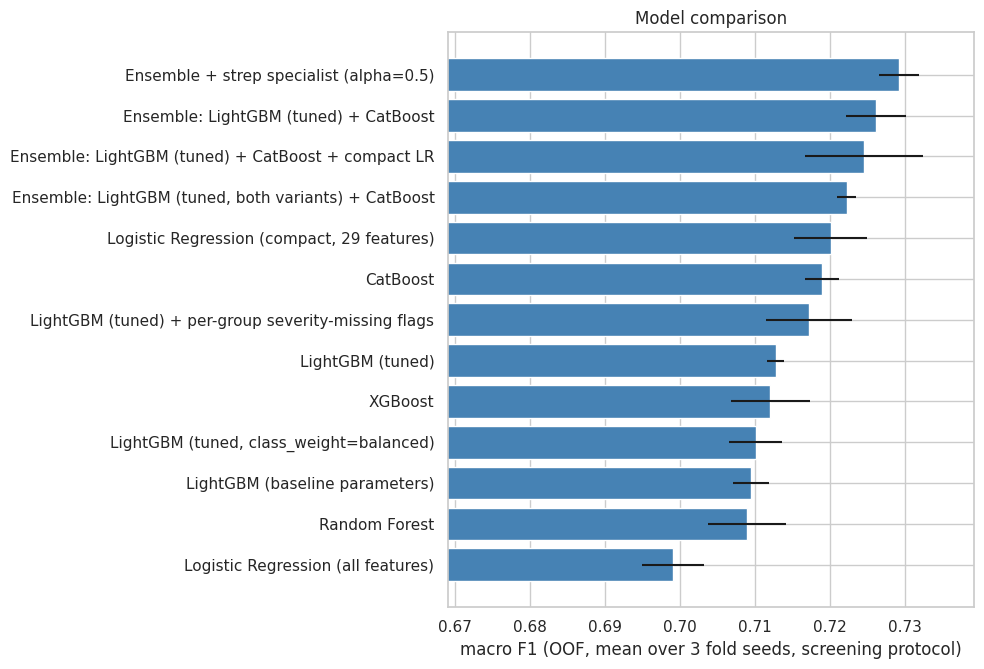

In [40]:
results = pd.DataFrame(RESULTS).T.sort_values("macro_f1_weighted", ascending=False)
display(results.round(4))

plot_results = results[results.index != "Dummy (class prior)"].sort_values("macro_f1_weighted")
fig, ax = plt.subplots(figsize=(10, 0.45 * len(plot_results) + 1))
ax.barh(plot_results.index, plot_results["macro_f1_weighted"], xerr=plot_results["std"], color="steelblue")
ax.set_xlim(plot_results["macro_f1_weighted"].min() - 0.03, plot_results["macro_f1_weighted"].max() + 0.01)
ax.set_xlabel("macro F1 (OOF, mean over 3 fold seeds, screening protocol)")
ax.set_title("Model comparison")
plt.tight_layout()
plt.show()

### 6.9 Fully nested evaluation of the final candidates

The three strongest candidates without additional, below-noise components are evaluated with the fully nested procedure:

1. The outer split is the same 5-fold split used by `run_cv` for each fold seed, so the outer-validation probabilities are the stored OOF predictions.
2. Inside each outer-training part, a 4-fold inner cross-validation produces OOF predictions that never involve the outer-validation rows, and the strep weight is chosen on those.
3. The chosen weight is applied to the outer-validation probabilities.

The table also reports the screening score of each candidate for comparison.

In [41]:
MODEL_SPECS = {"LightGBM (tuned)": (make_lgb(BEST_LGB_PARAMS), X_lgb), "CatBoost": (make_catboost, X_str)}
CANDIDATES = {"Ensemble: LightGBM (tuned) + CatBoost": ["LightGBM (tuned)", "CatBoost"],
              "LightGBM (tuned)": ["LightGBM (tuned)"],
              "CatBoost": ["CatBoost"]}


def inner_oof(name, seed, outer_train):
    make_model, X = MODEL_SPECS[name]
    inner = StratifiedKFold(n_splits=N_FOLDS - 1, shuffle=True, random_state=seed)
    oof = np.zeros((len(outer_train), len(CLASSES)))
    for in_tr, in_va in inner.split(outer_train, y[outer_train]):
        model = make_model(seed)
        model.fit(X.iloc[outer_train[in_tr]], y[outer_train[in_tr]])
        oof[in_va] = model.predict_proba(X.iloc[outer_train[in_va]])
    return oof


NESTED_PRED = {k: [] for k in CANDIDATES}
NESTED_WEIGHTS = {k: [] for k in CANDIDATES}
nested_rows = []
for s_idx, seed in enumerate(CV_SEEDS):
    outer = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    pred = {k: np.zeros(len(y), dtype=int) for k in CANDIDATES}
    weights = {k: [] for k in CANDIDATES}
    for tr_i, va_i in outer.split(X_lgb, y):
        fresh = {m: inner_oof(m, seed, tr_i) for m in MODEL_SPECS}
        for name, members in CANDIDATES.items():
            g = find_strep_weight(np.mean([fresh[m] for m in members], axis=0), y[tr_i])
            w = np.ones(len(CLASSES))
            w[I_STREP] = g
            prob = np.mean([OOF[m][s_idx][va_i] for m in members], axis=0)
            pred[name][va_i] = (prob * w).argmax(axis=1)
            weights[name].append(round(g, 2))
    for name, members in CANDIDATES.items():
        NESTED_PRED[name].append(pred[name])
        NESTED_WEIGHTS[name].append(weights[name])
        screening_pred, _ = screening_weighted_pred(np.mean([OOF[m][s_idx] for m in members], axis=0))
        nested_rows.append({"model": name, "seed": seed,
                            "screening_f1": f1_score(y, screening_pred, average="macro"),
                            "nested_f1": f1_score(y, pred[name], average="macro"),
                            "strep_f1_nested": f1_score(y, pred[name], average=None)[I_STREP],
                            "nested_weights": weights[name]})
    print("finished seed", seed)

nested_table = pd.DataFrame(nested_rows)
nested_table["difference"] = nested_table["nested_f1"] - nested_table["screening_f1"]
display(nested_table.round(4))
nested_summary = nested_table.groupby("model")[["screening_f1", "nested_f1", "strep_f1_nested", "difference"]].agg(["mean", "std"])
display(nested_summary.round(4))

finished seed 42
finished seed 7
finished seed 2024


,model,seed,screening_f1,nested_f1,strep_f1_nested,nested_weights,difference
0,Ensemble: LightGBM (tuned) + CatBoost,42,0.7205,0.7235,0.4136,"[2.7, 3.0, 2.2, 2.9, 2.4]",0.0030
1,LightGBM (tuned),42,0.7129,0.7174,0.3983,"[2.3, 3.2, 3.1, 3.3, 2.0]",0.0045
2,CatBoost,42,0.7221,0.7110,0.3983,"[2.7, 2.8, 3.0, 3.9, 3.3]",-0.0111
3,Ensemble: LightGBM (tuned) + CatBoost,7,0.7291,0.7193,0.4041,"[2.1, 2.7, 3.8, 2.3, 3.3]",-0.0098
4,LightGBM (tuned),7,0.7141,0.7179,0.4094,"[2.0, 2.7, 3.5, 2.9, 3.6]",0.0039
5,CatBoost,7,0.7178,0.7174,0.4055,"[2.8, 2.4, 2.9, 2.2, 3.0]",-0.0004
6,Ensemble: LightGBM (tuned) + CatBoost,2024,0.7287,0.7172,0.4000,"[2.8, 3.7, 2.3, 3.4, 3.5]",-0.0114
7,LightGBM (tuned),2024,0.7112,0.7182,0.4025,"[2.6, 3.0, 3.6, 2.0, 3.4]",0.0070
8,CatBoost,2024,0.7168,0.7101,0.3805,"[2.4, 2.8, 3.3, 3.3, 2.5]",-0.0068


screening_f1         nested_f1         strep_f1_nested         difference        
                                              mean     std      mean     std            mean     std       mean     std
model                                                                                                                  
CatBoost                                    0.7189  0.0028    0.7128  0.0040          0.3948  0.0129    -0.0061  0.0054
Ensemble: LightGBM (tuned) + CatBoost       0.7261  0.0049    0.7200  0.0032          0.4059  0.0070    -0.0061  0.0079
LightGBM (tuned)                            0.7127  0.0014    0.7178  0.0004          0.4034  0.0056     0.0051  0.0017

The screening and nested scores differ by about ±0.006, and the sign of the difference depends on the model (lower for the ensemble and CatBoost, higher for LightGBM). The screening protocol therefore adds noise of roughly the size of the acceptance threshold rather than a systematic optimistic bias, and screening differences smaller than about 0.01 are treated as ties. Under full nesting the ensemble scores 0.720 ± 0.003, LightGBM 0.718 ± 0.000 and CatBoost 0.713 ± 0.004.

### 6.10 Model selection

- **Final model: average of the tuned LightGBM and CatBoost.** It has the highest nested score and the same log loss as LightGBM alone, and it combines two different algorithms whose errors partly offset each other. Its lead over LightGBM alone falls within noise.
- **Second submission: tuned LightGBM alone.** It is the most consistent candidate across fold seeds under full nesting and scores above CatBoost alone.
- **Not adopted:** the strep specialist, the compact logistic regression as a third member, the per-group severity-missing flags and the raw symptom labels. Their screening gains are smaller than the screening noise.

In [42]:
FINAL_NAME = "Ensemble: LightGBM (tuned) + CatBoost"
FINAL_MEMBERS = CANDIDATES[FINAL_NAME]
BACKUP_NAME = "LightGBM (tuned)"
BACKUP_MEMBERS = CANDIDATES[BACKUP_NAME]

## 7. Final Model Evaluation and Error Analysis

The evaluation uses the fold split of the first fold seed (42). Probabilities are the out-of-fold ensemble probabilities, and class predictions apply the strep weight chosen by the fully nested procedure of Section 6.9.

### 7.1 Overall and per-class performance

In [43]:
EVAL_SEED_IDX = 0
final_prob = np.mean([OOF[m][EVAL_SEED_IDX] for m in FINAL_MEMBERS], axis=0)
final_pred = NESTED_PRED[FINAL_NAME][EVAL_SEED_IDX]
print("fold seed:", CV_SEEDS[EVAL_SEED_IDX], "| nested strep weight per outer fold:", NESTED_WEIGHTS[FINAL_NAME][EVAL_SEED_IDX])
print(f"macro F1: {f1_score(y, final_pred, average='macro'):.4f}")
print(classification_report(y, final_pred, target_names=CLASSES, digits=3))

auc_table = pd.DataFrame({
    "roc_auc_ovr": [roc_auc_score(y == k, final_prob[:, k]) for k in range(len(CLASSES))],
    "pr_auc": [average_precision_score(y == k, final_prob[:, k]) for k in range(len(CLASSES))],
    "prevalence": [(y == k).mean() for k in range(len(CLASSES))],
}, index=CLASSES)
display(auc_table.round(3))

fold seed: 42 | nested strep weight per outer fold: [2.7, 3.0, 2.2, 2.9, 2.4]
macro F1: 0.7235
                   precision    recall  f1-score   support

 acute_bronchitis      0.860     0.843     0.851       940
strep_pharyngitis      0.371     0.467     0.414       195
viral_pharyngitis      0.751     0.676     0.712       985
  viral_sinusitis      0.898     0.939     0.918      1480

         accuracy                          0.816      3600
        macro avg      0.720     0.731     0.724      3600
     weighted avg      0.819     0.816     0.817      3600



,roc_auc_ovr,pr_auc,prevalence
acute_bronchitis,0.968,0.930,0.261
strep_pharyngitis,0.920,0.409,0.054
viral_pharyngitis,0.922,0.796,0.274
viral_sinusitis,0.984,0.976,0.411


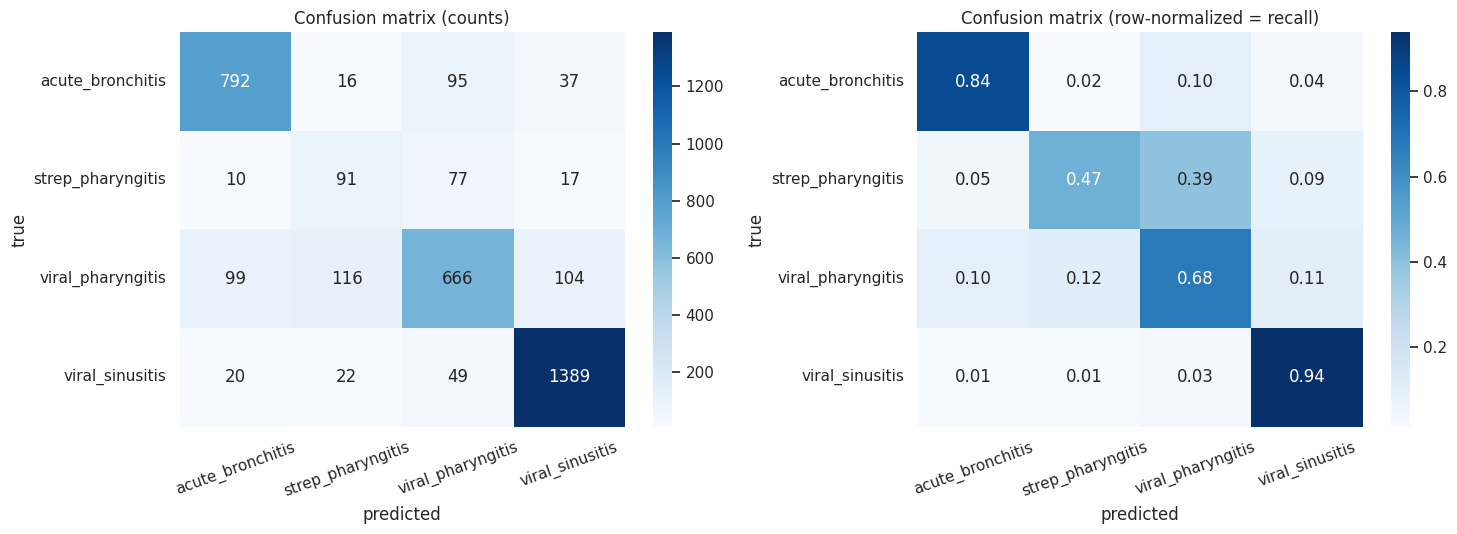

In [44]:
cm = confusion_matrix(y, final_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(pd.DataFrame(cm_norm, index=CLASSES, columns=CLASSES), annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalized = recall)")
for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 7.2 Most frequent errors

In [45]:
PROFILE_COLS = ["no_cough", "sym_fever", "sym_nasal", "sym_systemic", "sym_dyspnea", "sym_secretion",
                "child_3_14", "age", "sevmax_throat", "centor_partial", "n_symptoms"]
err = train_df[["target_class"] + PROFILE_COLS].copy()
err["predicted"] = np.array(CLASSES)[final_pred]
err["correct"] = err["target_class"] == err["predicted"]
err["confidence"] = final_prob.max(axis=1)

confusions = err[~err["correct"]].groupby(["target_class", "predicted"]).size().sort_values(ascending=False)
display(confusions.rename("count").to_frame())


def profile(case_masks):
    table = pd.DataFrame({name: err.loc[mask, PROFILE_COLS].mean() for name, mask in case_masks.items()}).T
    table.insert(0, "n", [int(mask.sum()) for mask in case_masks.values()])
    return table.round(2)


def is_true(c):
    return err["target_class"] == c


def is_pred(c):
    return err["predicted"] == c

count
target_class      predicted               
viral_pharyngitis strep_pharyngitis    116
                  viral_sinusitis      104
                  acute_bronchitis      99
acute_bronchitis  viral_pharyngitis     95
strep_pharyngitis viral_pharyngitis     77
viral_sinusitis   viral_pharyngitis     49
acute_bronchitis  viral_sinusitis       37
viral_sinusitis   strep_pharyngitis     22
                  acute_bronchitis      20
strep_pharyngitis viral_sinusitis       17
acute_bronchitis  strep_pharyngitis     16
strep_pharyngitis acute_bronchitis      10

### 7.3 Strep pharyngitis: the underrepresented class

,n,no_cough,sym_fever,sym_nasal,sym_systemic,sym_dyspnea,sym_secretion,child_3_14,age,sevmax_throat,centor_partial,n_symptoms
"strep, correct",91,1.00,0.63,0.49,0.71,0.05,0.05,0.55,28.79,63.85,2.16,3.02
strep -> viral_pharyngitis,77,0.95,0.51,0.53,0.94,0.04,0.05,0.16,40.83,49.49,1.61,3.26
strep -> other classes,27,0.81,0.48,0.70,0.30,0.11,0.41,0.48,26.41,44.13,1.78,3.07
"viral_pharyngitis, correct",666,0.48,0.47,0.48,0.87,0.04,0.05,0.12,39.52,44.45,1.06,3.47
viral_pharyngitis -> strep,116,1.00,0.66,0.57,0.72,0.01,0.04,0.44,29.59,55.36,2.10,3.03


separability of strep vs viral pharyngitis among pharyngitis cases (ROC AUC): 0.8117


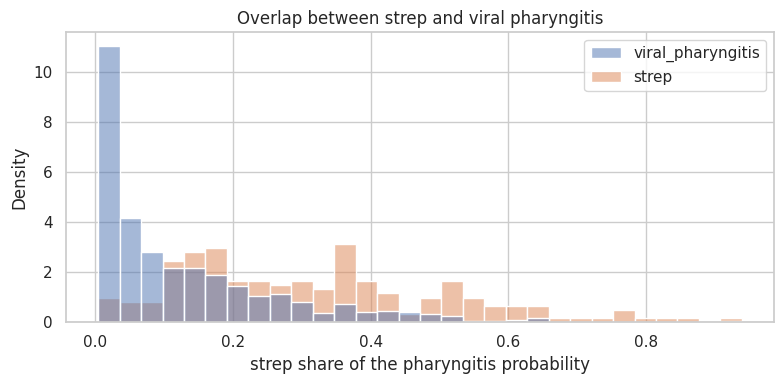

In [46]:
display(profile({
    "strep, correct": is_true("strep_pharyngitis") & err["correct"],
    "strep -> viral_pharyngitis": is_true("strep_pharyngitis") & is_pred("viral_pharyngitis"),
    "strep -> other classes": is_true("strep_pharyngitis") & ~err["correct"] & ~is_pred("viral_pharyngitis"),
    "viral_pharyngitis, correct": is_true("viral_pharyngitis") & err["correct"],
    "viral_pharyngitis -> strep": is_true("viral_pharyngitis") & is_pred("strep_pharyngitis"),
}))

phar_share = final_prob[pharyngitis, I_STREP] / (final_prob[pharyngitis, I_STREP] + final_prob[pharyngitis, I_VIRAL_PHAR])
print(f"separability of strep vs viral pharyngitis among pharyngitis cases (ROC AUC): {roc_auc_score(y_phar, phar_share):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(x=phar_share, hue=np.where(y_phar == 1, "strep", "viral_pharyngitis"), bins=30,
             stat="density", common_norm=False, ax=ax)
ax.set_xlabel("strep share of the pharyngitis probability")
ax.set_title("Overlap between strep and viral pharyngitis")
plt.tight_layout()
plt.show()

### 7.4 Acute bronchitis versus viral pharyngitis

In [47]:
display(profile({
    "bronchitis, correct": is_true("acute_bronchitis") & err["correct"],
    "bronchitis -> viral_pharyngitis": is_true("acute_bronchitis") & is_pred("viral_pharyngitis"),
    "viral_pharyngitis, correct": is_true("viral_pharyngitis") & err["correct"],
    "viral_pharyngitis -> bronchitis": is_true("viral_pharyngitis") & is_pred("acute_bronchitis"),
}))

,n,no_cough,sym_fever,sym_nasal,sym_systemic,sym_dyspnea,sym_secretion,child_3_14,age,sevmax_throat,centor_partial,n_symptoms
"bronchitis, correct",792,0.26,0.83,0.85,0.83,0.70,0.78,0.16,38.83,36.37,1.26,5.95
bronchitis -> viral_pharyngitis,95,0.34,0.67,0.67,0.87,0.11,0.13,0.15,37.70,40.58,1.16,4.04
"viral_pharyngitis, correct",666,0.48,0.47,0.48,0.87,0.04,0.05,0.12,39.52,44.45,1.06,3.47
viral_pharyngitis -> bronchitis,99,0.19,0.74,0.78,0.89,0.36,0.51,0.24,38.62,44.50,1.17,5.40


### 7.5 Recall by age group and prediction confidence

recall by age group:


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
age_group,,,,
0-2,1.000,NaN,1.000,1.000
3-14,0.848,0.662,0.479,0.945
15-44,0.837,0.235,0.729,0.942
45-64,0.831,0.395,0.747,0.949
65+,0.885,0.458,0.589,0.901


encounters by age group:


target_class,acute_bronchitis,strep_pharyngitis,viral_pharyngitis,viral_sinusitis
age_group,,,,
0-2,2.0,NaN,2.0,1.0
3-14,151.0,74.0,165.0,199.0
15-44,399.0,51.0,406.0,659.0
45-64,249.0,43.0,285.0,395.0
65+,122.0,24.0,112.0,203.0


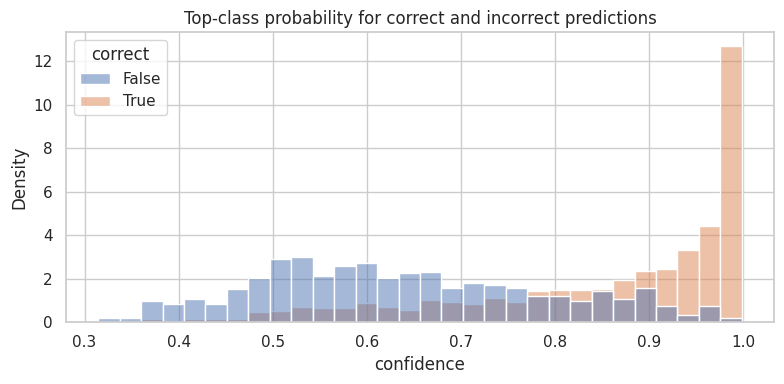

,mean,size
confidence,,
"(0.0, 0.5]",0.399,208
"(0.5, 0.7]",0.580,750
"(0.7, 0.9]",0.823,1015
"(0.9, 1.0]",0.974,1627


In [48]:
err["age_group"] = pd.cut(err["age"], bins=AGE_BINS, right=False, labels=AGE_LABELS)
recall_by_age = err.groupby(["age_group", "target_class"], observed=True)["correct"].mean().unstack()
count_by_age = err.groupby(["age_group", "target_class"], observed=True).size().unstack()
print("recall by age group:")
display(recall_by_age.round(3))
print("encounters by age group:")
display(count_by_age)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=err, x="confidence", hue="correct", bins=30, stat="density", common_norm=False, ax=ax)
ax.set_title("Top-class probability for correct and incorrect predictions")
plt.tight_layout()
plt.show()
display(err.groupby(pd.cut(err["confidence"], [0, 0.5, 0.7, 0.9, 1.0]), observed=True)["correct"].agg(["mean", "size"]).round(3))

## 8. Model Interpretability

The tuned LightGBM is refit on all training data for interpretation. SHAP values are computed with LightGBM's built-in TreeSHAP (`pred_contrib=True`); for the multiclass model they are expressed in log-odds (softmax margin) units, one set per class.

### 8.1 Gain-based feature importance

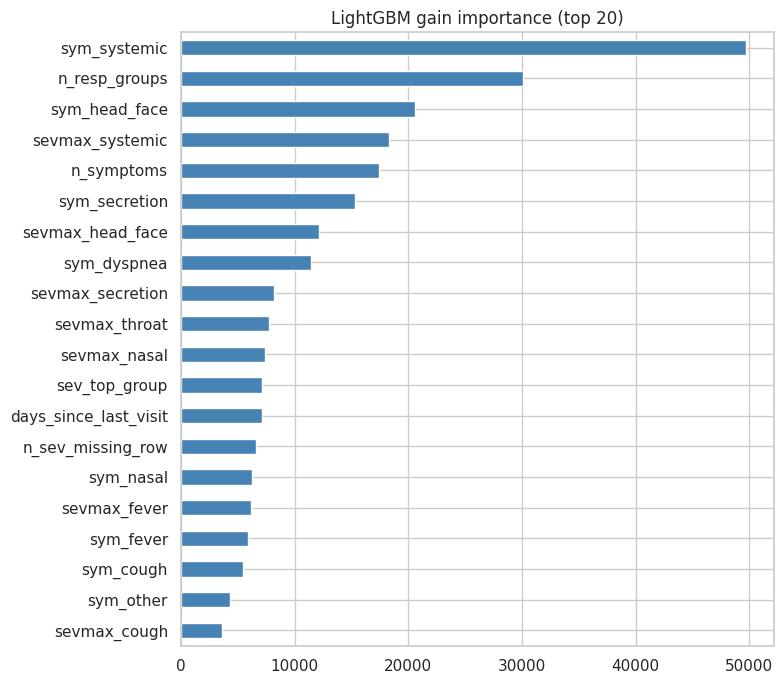

In [49]:
interp_model = lgb.LGBMClassifier(**BEST_LGB_PARAMS, random_state=SEED, verbose=-1)
interp_model.fit(X_lgb, y)

gain = pd.Series(interp_model.booster_.feature_importance(importance_type="gain"),
                 index=interp_model.booster_.feature_name()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
gain.head(20)[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("LightGBM gain importance (top 20)")
plt.tight_layout()
plt.show()

### 8.2 SHAP: global and per-class importance

additivity check, max |sum of SHAP + base - raw margin|: 2.042810365310288e-14


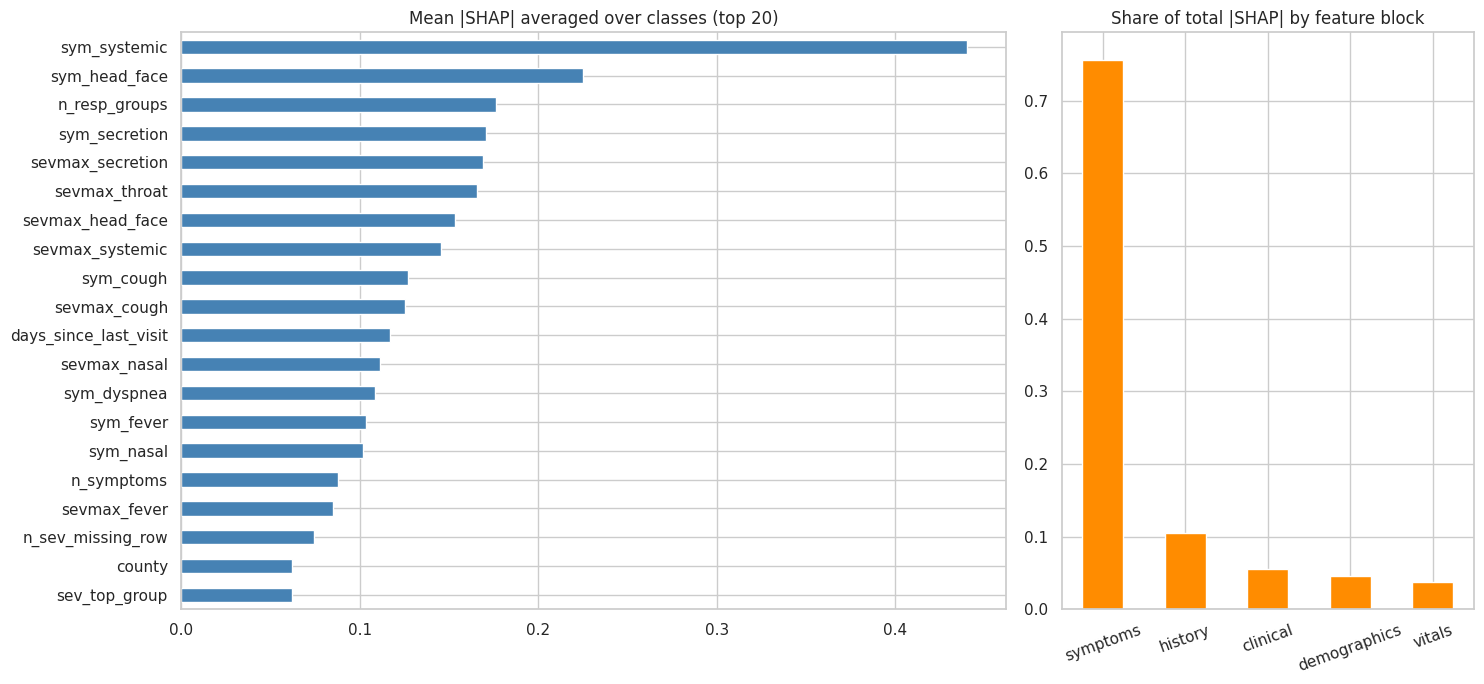

,share
symptoms,0.756
history,0.105
clinical,0.056
demographics,0.046
vitals,0.037


In [50]:
contrib = np.asarray(interp_model.predict(X_lgb, pred_contrib=True))
n_feat = len(FEATURES)
contrib = contrib.reshape(len(X_lgb), len(CLASSES), n_feat + 1)
shap_values = contrib[:, :, :n_feat]
shap_base = contrib[:, :, n_feat]
raw_margin = interp_model.predict(X_lgb, raw_score=True)
print("additivity check, max |sum of SHAP + base - raw margin|:", float(np.abs(contrib.sum(axis=2) - raw_margin).max()))

mean_abs = pd.DataFrame(np.abs(shap_values).mean(axis=0).T, index=FEATURES, columns=CLASSES)
global_importance = mean_abs.mean(axis=1).sort_values(ascending=False)
block_share = (global_importance.groupby(FEATURE_TO_BLOCK).sum() / global_importance.sum()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [2, 1]})
global_importance.head(20)[::-1].plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Mean |SHAP| averaged over classes (top 20)")
block_share.plot(kind="bar", ax=axes[1], color="darkorange", rot=20)
axes[1].set_title("Share of total |SHAP| by feature block")
plt.tight_layout()
plt.show()
display(block_share.round(3).rename("share").to_frame())

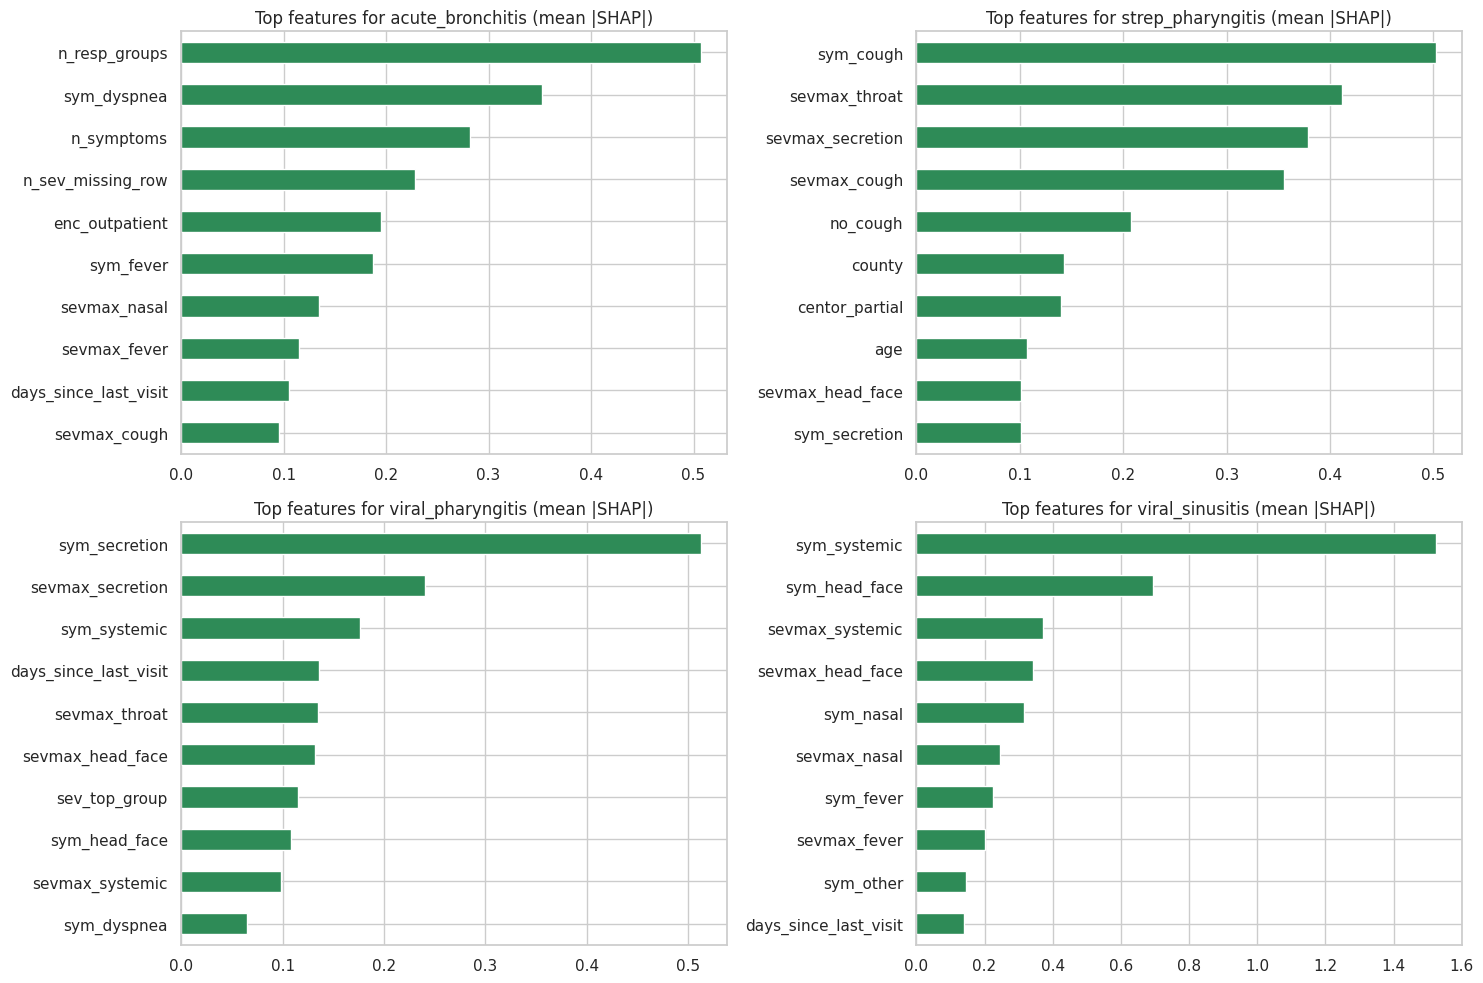

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, cls in zip(axes.ravel(), CLASSES):
    mean_abs[cls].sort_values(ascending=False).head(10)[::-1].plot(kind="barh", ax=ax, color="seagreen")
    ax.set_title(f"Top features for {cls} (mean |SHAP|)")
plt.tight_layout()
plt.show()

### 8.3 SHAP direction of effect for strep pharyngitis

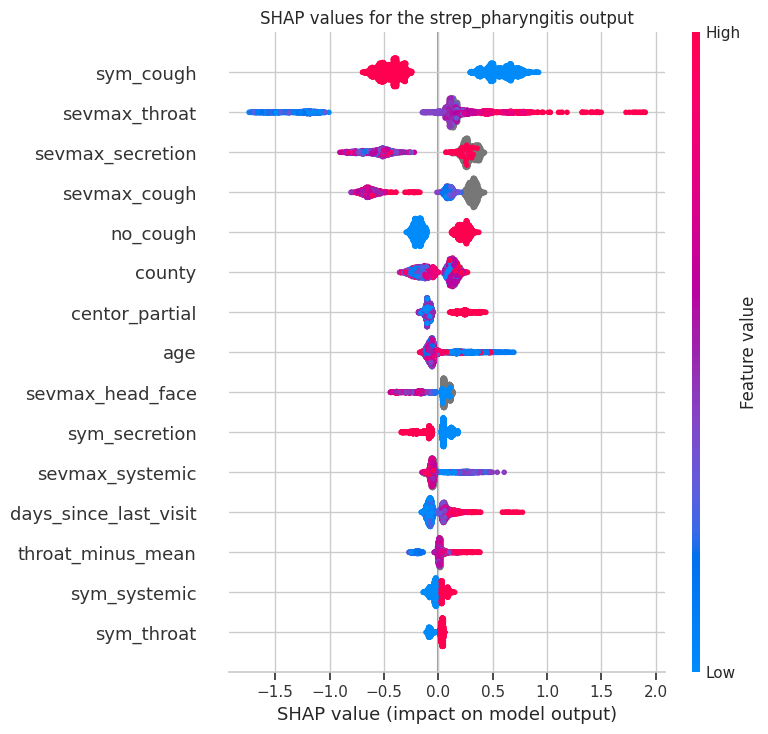

In [52]:
X_display = X_lgb.copy()
for c in CAT_COLS:
    X_display[c] = X_display[c].cat.codes.replace(-1, np.nan)

shap.summary_plot(shap_values[:, I_STREP, :], X_display, max_display=15, show=False)
plt.title("SHAP values for the strep_pharyngitis output")
plt.tight_layout()
plt.show()

### 8.4 Local explanations

Two training encounters with true label strep are explained with the full-data model: the correctly predicted case with the highest OOF strep probability, and the case missed as viral pharyngitis with the highest OOF viral probability.

Strep correctly identified: OOF probabilities {'acute_bronchitis': 0.002, 'strep_pharyngitis': 0.936, 'viral_pharyngitis': 0.061, 'viral_sinusitis': 0.001}


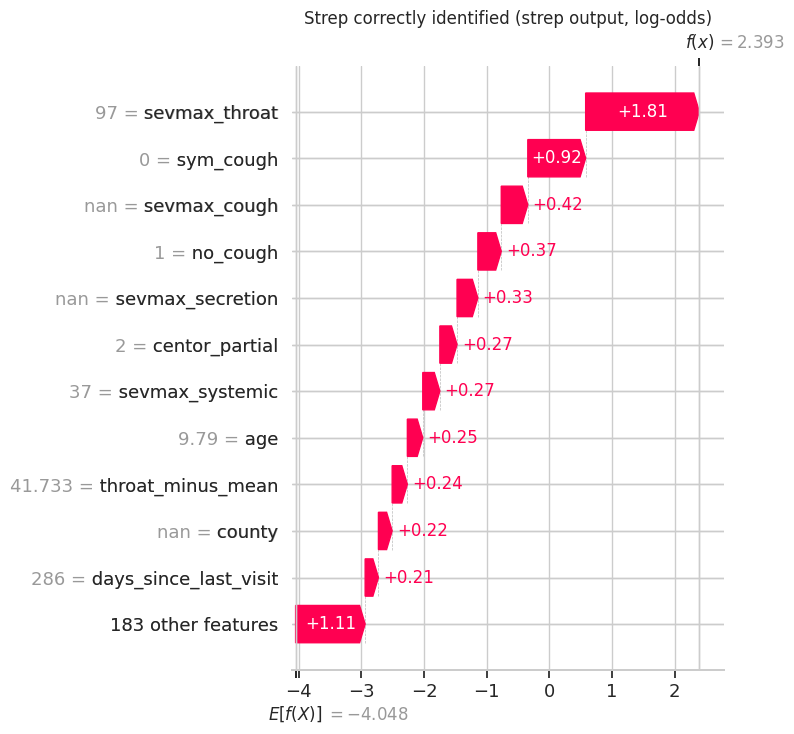

Strep missed as viral pharyngitis: OOF probabilities {'acute_bronchitis': 0.013, 'strep_pharyngitis': 0.044, 'viral_pharyngitis': 0.922, 'viral_sinusitis': 0.021}


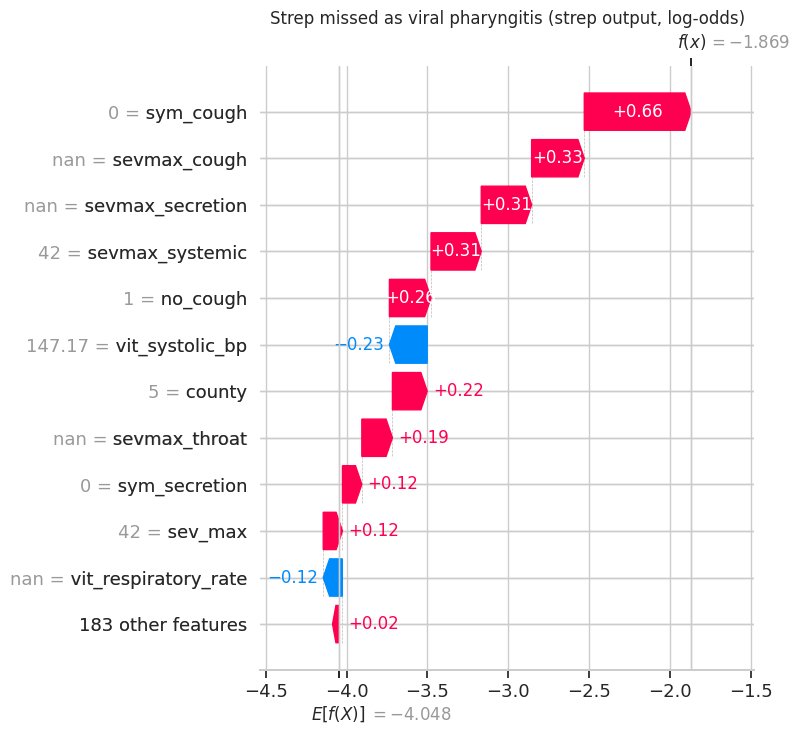

In [53]:
is_strep = y == I_STREP
hit_idx = np.where(is_strep & (final_pred == I_STREP))[0]
miss_idx = np.where(is_strep & (final_pred == I_VIRAL_PHAR))[0]
examples = []
if len(hit_idx) > 0:
    examples.append(("Strep correctly identified", hit_idx[np.argmax(final_prob[hit_idx, I_STREP])]))
if len(miss_idx) > 0:
    examples.append(("Strep missed as viral pharyngitis", miss_idx[np.argmax(final_prob[miss_idx, I_VIRAL_PHAR])]))

for title, j in examples:
    print(f"{title}: OOF probabilities", {c: round(float(p), 3) for c, p in zip(CLASSES, final_prob[j])})
    explanation = shap.Explanation(values=shap_values[j, I_STREP], base_values=shap_base[j, I_STREP],
                                   data=X_display.iloc[j].values, feature_names=FEATURES)
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"{title} (strep output, log-odds)")
    plt.tight_layout()
    plt.show()

### 8.5 Coefficients of the compact logistic regression

The compact logistic regression is nearly as accurate as the tree ensembles (Section 6.8) while being fully transparent. Its standardized coefficients show how each feature moves the log-odds of each class.

In [ ]:
lr_model = make_logreg_compact(SEED).fit(X_lgb[COMPACT_FEATURES], y)
coef = pd.DataFrame(lr_model[-1].coef_.T, index=lr_model[:-1].get_feature_names_out(), columns=CLASSES)
top_coef = coef.loc[coef.abs().max(axis=1).sort_values(ascending=False).head(20).index]

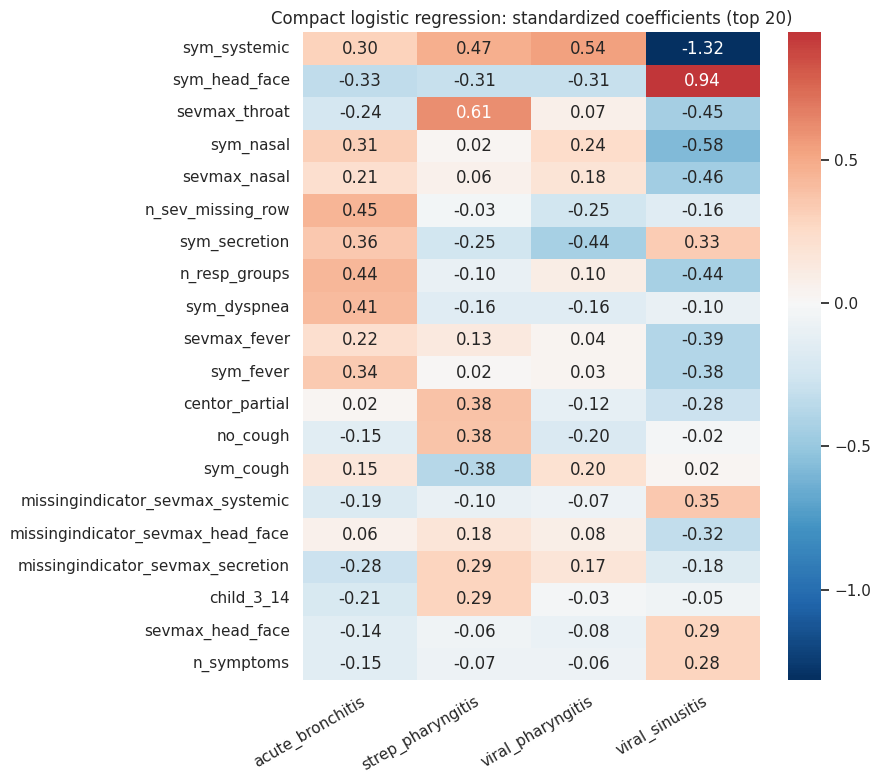

In [58]:
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(top_coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Compact logistic regression: standardized coefficients (top 20)")
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=30,
    ha="right",
    rotation_mode="anchor"
)
plt.tight_layout()
plt.show()

## 9. Final Training and Submission

Each member is refit on all training data with five seeds and its test probabilities are averaged. The strep weight is chosen on the full averaged OOF probabilities. Two files are produced: the final ensemble and the LightGBM second submission. Each file is checked for row count, missing predictions, row order, and the agreement between the test prediction distribution and the OOF prediction distribution.

In [55]:
prob_lgb = np.zeros((len(test_df), len(CLASSES)))
prob_cb = np.zeros((len(test_df), len(CLASSES)))
for s in FINAL_SEEDS:
    model_lgb = make_lgb(BEST_LGB_PARAMS)(s)
    model_lgb.fit(X_lgb, y)
    prob_lgb += model_lgb.predict_proba(X_lgb_test) / len(FINAL_SEEDS)
    model_cb = make_catboost(s)
    model_cb.fit(X_str, y)
    prob_cb += model_cb.predict_proba(X_str_test) / len(FINAL_SEEDS)
    print("finished seed", s)

prob_final = (prob_lgb + prob_cb) / 2
prob_backup = prob_lgb
final_oof = np.mean(ensemble_oof(FINAL_MEMBERS), axis=0)
backup_oof = np.mean(ensemble_oof(BACKUP_MEMBERS), axis=0)
w_final = find_strep_weight(final_oof, y)
w_backup = find_strep_weight(backup_oof, y)
print(f"strep weight: final ensemble {w_final:.1f} | LightGBM {w_backup:.1f}")

finished seed 42
finished seed 7
finished seed 2024
finished seed 11
finished seed 99
strep weight: final ensemble 2.4 | LightGBM 2.8


In [56]:
def make_submission(prob, oof, w_strep, path):
    w = np.ones(len(CLASSES))
    w[I_STREP] = w_strep
    pred = np.array(CLASSES)[(prob * w).argmax(axis=1)]
    sub = sample_sub[["sample_id"]].merge(pd.DataFrame({"sample_id": test_df["sample_id"].values, "target_class": pred}),
                                          on="sample_id", how="left")
    n_missing = int(sub["target_class"].isna().sum())
    same_order = bool((sub["sample_id"].values == sample_sub["sample_id"].values).all())
    print(f"{path}: rows {len(sub)} | missing predictions {n_missing} | order matches sample_submission {same_order}")
    dist = pd.concat([
        sub["target_class"].value_counts(normalize=True),
        pd.Series(np.array(CLASSES)[(oof * w).argmax(axis=1)]).value_counts(normalize=True),
        train["target_class"].value_counts(normalize=True),
    ], axis=1, keys=["test_prediction", "oof_prediction", "train_label"]).round(3)
    display(dist)
    sub.to_csv(path, index=False)
    return sub


submission_final = make_submission(prob_final, final_oof, w_final, "submission_lgbm_catboost.csv")
submission_backup = make_submission(prob_backup, backup_oof, w_backup, "submission_lgbm.csv")

submission_lgbm_catboost.csv: rows 1400 | missing predictions 0 | order matches sample_submission True


,test_prediction,oof_prediction,train_label
viral_sinusitis,0.409,0.429,0.411
acute_bronchitis,0.263,0.260,0.261
viral_pharyngitis,0.262,0.251,0.274
strep_pharyngitis,0.066,0.060,0.054


submission_lgbm.csv: rows 1400 | missing predictions 0 | order matches sample_submission True


,test_prediction,oof_prediction,train_label
viral_sinusitis,0.403,0.427,0.411
acute_bronchitis,0.263,0.256,0.261
viral_pharyngitis,0.241,0.237,0.274
strep_pharyngitis,0.093,0.080,0.054
